# Manejo de la Data principal del Tour De Francia.


In [ ]:
import numpy as np
import pandas as pd
df=pd.read_csv("tour_dataset_final.csv")
dfPCS=pd.read_csv("PCS_GC.csv",sep=';')
dfPCS.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Year            190 non-null    int64  
 1   Rider           190 non-null    object 
 2   PCS_GC_Ranking  189 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 4.6+ KB


Como el objetivo final es hacer una clasificación, utilizaremos la variable **position** como nuestra variable respuesta, donde será **1** si se encuentra en el podio, es decir, si $y<=3$ y será **0** si no se encuentra en el podio, es decir, $y>3$

Además, Para la única observación cuyo valor de PCS GC Ranking no se encontraba disponible, correspondiente a Lance Armstrong en el Tour de Francia 2009, se realizó una imputación basada en la mediana del PCS GC Ranking de los corredores que obtuvieron posiciones de podio dentro del conjunto de entrenamiento. De esta manera, el valor imputado se obtuvo exclusivamente a partir de observaciones pertenecientes al conjunto utilizado para el entrenamiento de los modelos, evitando utilizar información del conjunto de prueba.


In [ ]:
df['podio'] = (df['Position'] <= 3).astype(int)
df['PCS_GC_Ranking']=dfPCS['PCS_GC_Ranking']
# Definir el rango de entrenamiento
train = df[df["Year"] <= 2020]

# Media del PCS GC Ranking de los corredores que ocuparon el podio
media_podio_train = train.loc[
    train["podio"] == 1,
    "PCS_GC_Ranking"
].median()

# Imputar el único valor faltante
df["PCS_GC_Ranking"] = df["PCS_GC_Ranking"].fillna(media_podio_train)

print("Media del podio en entrenamiento:", media_podio_train)
print("Valor imputado:", df.loc[
    df["Rider"].str.contains("Armstrong", case=False, na=False),
    "PCS_GC_Ranking"
])

Media del podio en entrenamiento: 1437.5
Valor imputado: 32    1437.5
Name: PCS_GC_Ranking, dtype: float64


Ahora bien, ya que hicimos la transformación de la variable respuesta, nos enfocaremos en estudiar la relación que tienen las variables predictoras y analizar si hay correlación entre ellas.

De momento, calcularemos el IMC(Indice de masa corporal) cuya fórmula es:

$\text{IMC} = \frac{\text{Peso (kg)}}{\text{Altura (m)}^2}$
Debido a que la variable que tenemos en el dataSet es: **Height_cm** es necesario convertirla a metros para así poder encontrar el IMC de forma correcta.

In [4]:
df["IMC"]=df["Weight_kg"]/(df["Height_cm"]/100)**2
y=df['podio']
dfp=df['Position']
X= df.drop(columns=['podio', 'Position','Weight_kg','Height_cm'])


elite = ['FRA', 'BEL', 'ESP', 'ITA', 'GBR']
medio = ['LUX', 'SLO', 'USA', 'DEN', 'NED']
bajo = ['SUI', 'GER', 'COL', 'AUS', 'IRL']

condiciones = [
    df['Country'].isin(elite),
    df['Country'].isin(medio),
    df['Country'].isin(bajo)
]

valores = [3, 2, 1]


X['country_cat'] = np.select(condiciones, valores, default=0)
X['PCS_GC_Ranking']=df['PCS_GC_Ranking']
X['country_cat'].tail(10)


180    2
181    2
182    3
183    0
184    3
185    3
186    3
187    2
188    0
189    1
Name: country_cat, dtype: int64

Transformaciones presentes en el documento:

In [5]:
epsilon = 1e-5
# 1. MIR
X['MIR'] = X['vertical_meters'] / X['IMC']
# 2. MIR relativo
X['MIRrel'] = X.groupby('Year')['MIR'].transform(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
# 3. Terrain ratio
X['terrain_ratio'] = (X['mountain'] + X['uphill']) / (
    X['flat'] + X['hills'] + epsilon
)
# 4. IMC promedio por año
X['IMC_mean_year'] = X.groupby('Year')['IMC'].transform('mean')
# 5. IDE
X['IDE'] = X['terrain_ratio'] * (X['IMC_mean_year'] / X['IMC'])
# 6. IDE relativo
X['IDErel'] = X.groupby('Year')['IDE'].transform(
    lambda x: (x - x.min()) / (x.max() - x.min())
)
# 7. CG
X['CG'] = (X['vertical_meters'] * X['IMC']) / (X['Experience_Years'] + 1)
# 8. Función general de normalización
def minmax_by_year(X, column):
    return X.groupby('Year')[column].transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )
# Ejemplo adicional
X['CGrel'] = minmax_by_year(X, 'CG')

Train y test temporal:

In [6]:
train_mask = X['Year'] <= 2020
test_mask = X['Year'] > 2020
X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()
y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()
print(X_train['Year'].min(), X_train['Year'].max())
print(X_test['Year'].min(), X_test['Year'].max())
y_test.info()

2006 2020
2021 2024
<class 'pandas.core.series.Series'>
Index: 40 entries, 150 to 189
Series name: podio
Non-Null Count  Dtype
--------------  -----
40 non-null     int64
dtypes: int64(1)
memory usage: 640.0 bytes


Eliminar variables que no se utilizarán en el modelo.

In [7]:
X_pruRid = X_test[['Year', 'Rider']].copy()# Copia util al final
X_train=X_train.drop(columns=['Year', 'Rider','Country','avg_speed_winner','MIR','IDE','CG'])
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 0 to 149
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age_Start_Tour            150 non-null    int64  
 1   Experience_Years          150 non-null    int64  
 2   Previous_Grand_Tours_Won  150 non-null    int64  
 3   distance                  150 non-null    float64
 4   vertical_meters           150 non-null    float64
 5   profile_score             150 non-null    float64
 6   startlist_quality         150 non-null    float64
 7   flat                      150 non-null    float64
 8   hills                     150 non-null    float64
 9   mountain                  150 non-null    float64
 10  flat_finish               150 non-null    float64
 11  uphill                    150 non-null    float64
 12  PCS_GC_Ranking            150 non-null    float64
 13  IMC                       150 non-null    float64
 14  country_cat    

### Pruebas de análisis exploratorio:

In [ ]:
# Construir el conjunto de datos para el análisis descriptivo
df_final = X_train.copy()
df_final['podio'] = y_train
# Variables numéricas
variables_numericas = df_final.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# No incluir la propia variable objetivo
variables_numericas.remove('podio')

# Estadísticos por grupo
descriptivos_podio = (
    df_final
    .groupby('podio')[variables_numericas]
    .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
)

print(descriptivos_podio)

      Age_Start_Tour                                     Experience_Years  \
               count       mean median       std min max            count   
podio                                                                       
0                105  29.133333   29.0  3.767438  22  39              105   
1                 45  29.311111   30.0  4.004669  21  37               45   

                                  ...    IDErel                     CGrel  \
           mean median       std  ...    median       std  min  max count   
podio                             ...                                       
0      7.723810    8.0  3.465476  ...  0.514937  0.306553  0.0  1.0   105   
1      7.844444    8.0  3.089245  ...  0.482602  0.340703  0.0  1.0    45   

                                               
           mean    median       std  min  max  
podio                                          
0      0.355849  0.256166  0.320755  0.0  1.0  
1      0.315165  0.256870  0.271433 

In [11]:
tabla_resumen = (
    df_final
    .groupby('podio')[variables_numericas]
    .agg(['mean', 'median', 'std'])
)

print(tabla_resumen)

      Age_Start_Tour                  Experience_Years                   \
                mean median       std             mean median       std   
podio                                                                     
0          29.133333   29.0  3.767438         7.723810    8.0  3.465476   
1          29.311111   30.0  4.004669         7.844444    8.0  3.089245   

      Previous_Grand_Tours_Won                      distance  ...  \
                          mean median       std         mean  ...   
podio                                                         ...   
0                     0.419048    0.0  1.385231  3498.906667  ...   
1                     0.822222    0.0  1.434777  3498.906667  ...   

      terrain_ratio IMC_mean_year                         IDErel            \
                std          mean     median       std      mean    median   
podio                                                                        
0          0.435261     20.444945  20.349708

### Boxplot con variables de interés deportivo.

<Figure size 600x400 with 0 Axes>

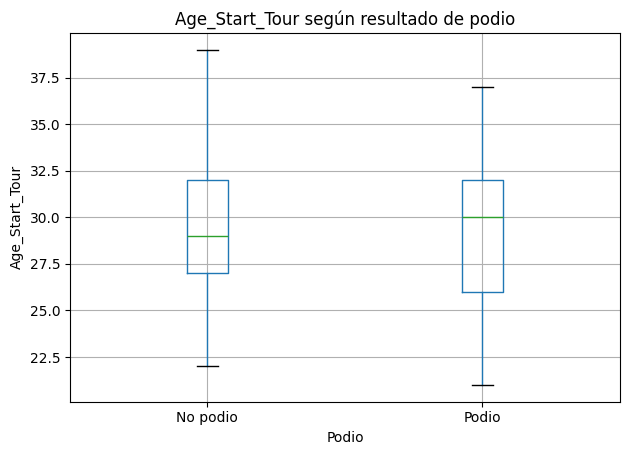

<Figure size 600x400 with 0 Axes>

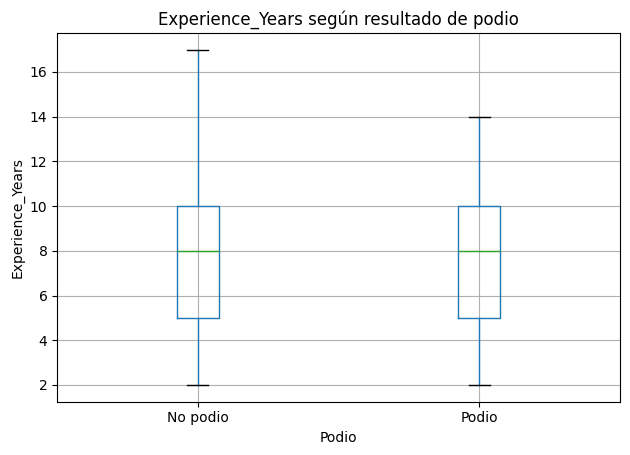

<Figure size 600x400 with 0 Axes>

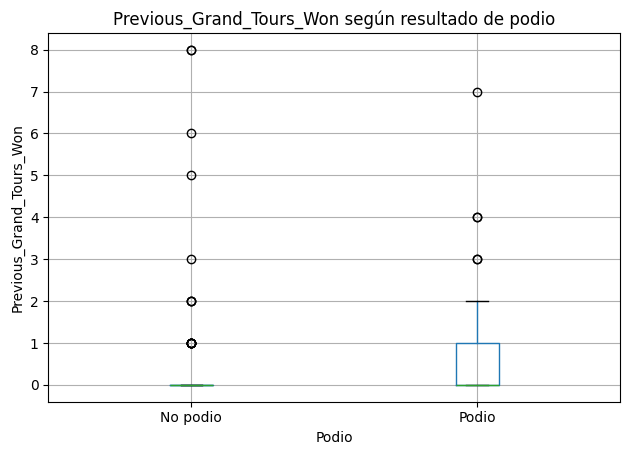

<Figure size 600x400 with 0 Axes>

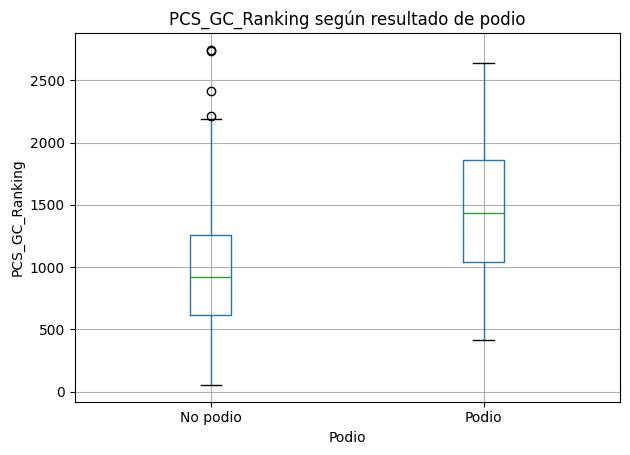

<Figure size 600x400 with 0 Axes>

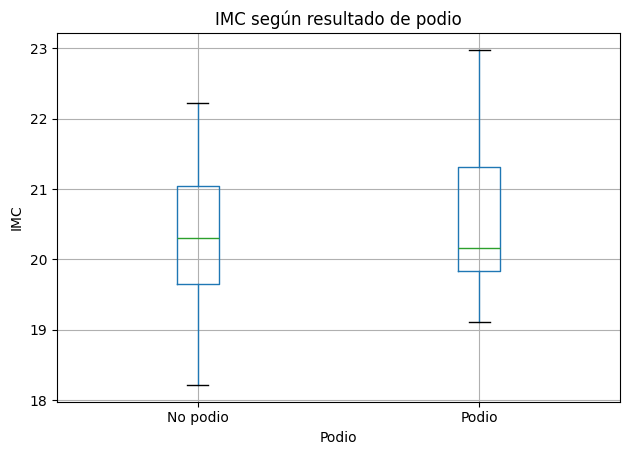

<Figure size 600x400 with 0 Axes>

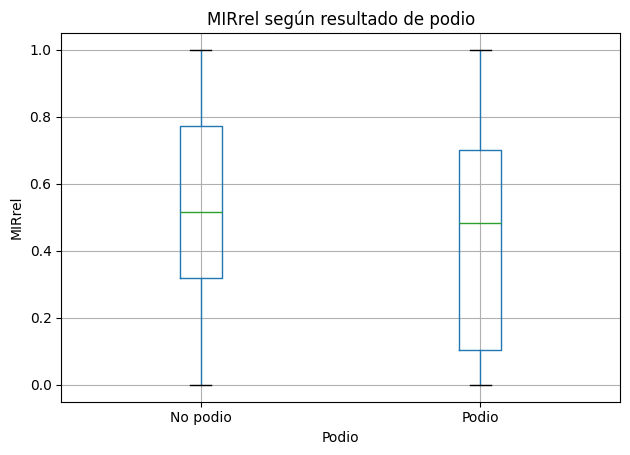

<Figure size 600x400 with 0 Axes>

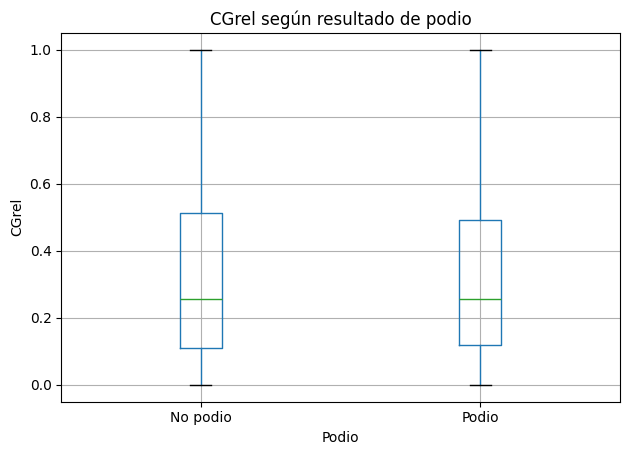

<Figure size 600x400 with 0 Axes>

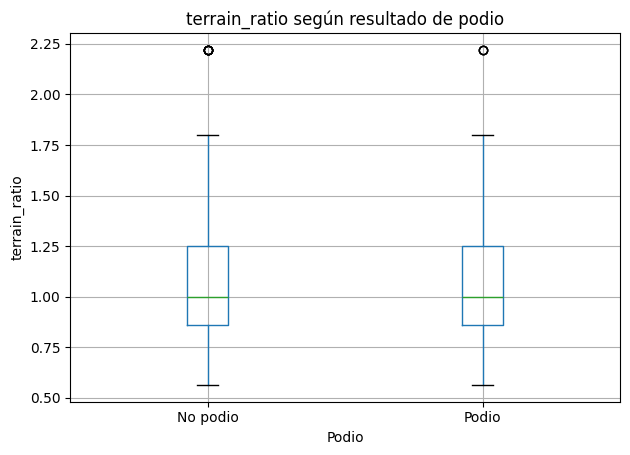

In [12]:
variables_boxplot = [
    'Age_Start_Tour',
    'Experience_Years',
    'Previous_Grand_Tours_Won',
    'PCS_GC_Ranking',
    'IMC',
    'MIRrel',
    'CGrel',
    'terrain_ratio'
]
for variable in variables_boxplot:

    plt.figure(figsize=(6, 4))

    df_final.boxplot(
        column=variable,
        by='podio'
    )

    plt.title(f'{variable} según resultado de podio')
    plt.suptitle('')
    plt.xlabel('Podio')
    plt.ylabel(variable)
    plt.xticks(
        [1, 2],
        ['No podio', 'Podio']
    )

    plt.tight_layout()
    plt.show()

In [13]:
variables_relevantes = [
    'PCS_GC_Ranking',
    'CGrel',
    'IMC',
    'terrain_ratio',
    'MIRrel',
    'Previous_Grand_Tours_Won',
    'Experience_Years',
    'startlist_quality'
]

comparacion = (
    df_final
    .groupby('podio')[variables_relevantes]
    .agg(['mean', 'median', 'std'])
)

print(comparacion)

      PCS_GC_Ranking                         CGrel                      \
                mean  median         std      mean    median       std   
podio                                                                    
0              998.4   920.0  540.867334  0.355849  0.256166  0.320755   
1             1484.3  1437.5  587.642636  0.315165  0.256870  0.271433   

             IMC                      terrain_ratio  ...    MIRrel  \
            mean     median       std          mean  ...       std   
podio                                                ...             
0      20.392290  20.305175  0.865877      1.140427  ...  0.306553   
1      20.567809  20.160701  0.981922      1.140427  ...  0.340703   

      Previous_Grand_Tours_Won                  Experience_Years         \
                          mean median       std             mean median   
podio                                                                     
0                     0.419048    0.0  1.385231      

### Frecuencias y proporciones en las categórias

In [14]:
tabla_pais = pd.crosstab(
    df_final['country_cat'],
    df_final['podio']
)

print(tabla_pais)

podio         0   1
country_cat        
0            14   2
1            17  10
2            21  10
3            53  23


In [15]:
tabla_pais_prop = pd.crosstab(
    df_final['country_cat'],
    df_final['podio'],
    normalize='index'
)

print(tabla_pais_prop)

podio               0         1
country_cat                    
0            0.875000  0.125000
1            0.629630  0.370370
2            0.677419  0.322581
3            0.697368  0.302632


Elegir los mejores parámetros utilizando CV con elastic-net

In [16]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

tscv = TimeSeriesSplit(n_splits=5)

elastic_net = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        max_iter=10000,
        random_state=42
    ))
])

param_grid = {
    'model__C': [0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10],
    'model__l1_ratio': [0.1, 0.25, 0.5, 0.75, 0.9, 1.0]
}

grid = GridSearchCV(
    elastic_net,
    param_grid,
    scoring='roc_auc',
    cv=tscv,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'model__C': 0.1, 'model__l1_ratio': 0.5}
0.7450292397660819


Mejores estimadores:

In [17]:
resultados = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    # Escalamiento SOLO con el entrenamiento del fold
    scaler = StandardScaler()

    X_fold_train_scaled = scaler.fit_transform(X_fold_train)

    # Elastic Net
    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        C=0.05,
        l1_ratio=0.1,
        max_iter=10000,
        random_state=42
    )

    model.fit(X_fold_train_scaled, y_fold_train)

    coefficients = model.coef_[0]

    for feature, coef in zip(X_train.columns, coefficients):

        resultados.append({
            'Fold': fold,
            'Feature': feature,
            'Coefficient': coef,
            'Selected': coef != 0
        })

In [18]:
df_estabilidad = pd.DataFrame(resultados)

estabilidad = (
    df_estabilidad
    .groupby('Feature')
    .agg(
        Folds_Selected=('Selected', 'sum'),
        Selection_Frequency=('Selected', 'mean'),
        Mean_Coefficient=('Coefficient', 'mean'),
        Mean_Abs_Coefficient=('Coefficient',
                              lambda x: np.mean(np.abs(x)))
    )
    .reset_index()
)

estabilidad = estabilidad.sort_values(
    'Selection_Frequency',
    ascending=False
)

print(estabilidad)

                     Feature  Folds_Selected  Selection_Frequency  \
7             PCS_GC_Ranking               5                  1.0   
1                      CGrel               4                  0.8   
4                        IMC               3                  0.6   
17             terrain_ratio               3                  0.6   
16         startlist_quality               2                  0.4   
2           Experience_Years               2                  0.4   
3                     IDErel               2                  0.4   
6                     MIRrel               2                  0.4   
8   Previous_Grand_Tours_Won               2                  0.4   
18                    uphill               2                  0.4   
12               flat_finish               2                  0.4   
19           vertical_meters               1                  0.2   
5              IMC_mean_year               1                  0.2   
9                country_cat      

Variables con total frecuencia:

In [19]:
stable_features = estabilidad.loc[
    estabilidad['Selection_Frequency'] >= 0.60,
    'Feature'
].tolist()

print("Variables estables:")
print(stable_features)

Variables estables:
['PCS_GC_Ranking', 'CGrel', 'IMC', 'terrain_ratio']


Si notamos, cada una de estas variables son características individuales de los corredores, lo que indica que son claves al momento de clasificar los podio de los No podios.

Matriz de correlación inferior, aprovechando la simetría de la matriz cuadrada:

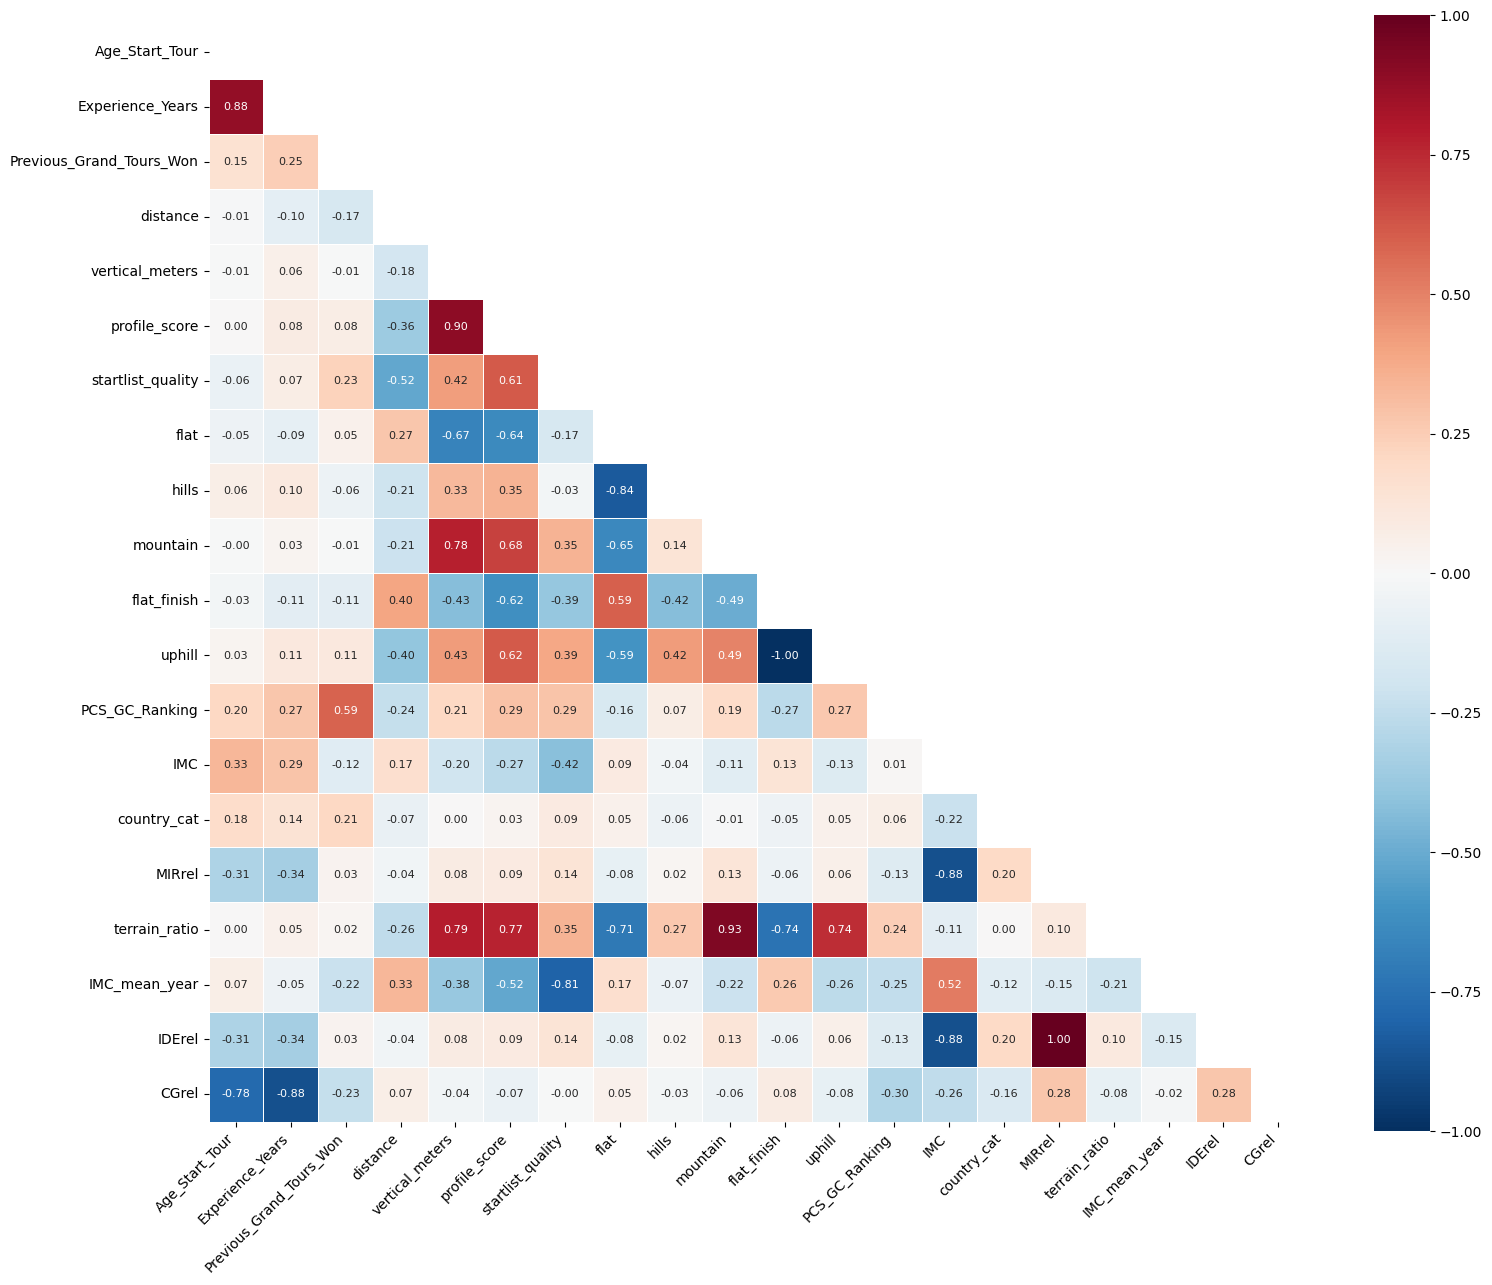

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

corr = X_train.corr()

mask = np.triu(
    np.ones_like(corr, dtype=bool)
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 8},
    vmin=-1,
    vmax=1
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Análisis:

El análisis de la matriz de correlación permite identificar relaciones lineales entre las variables del conjunto de datos, así como posibles problemas de multicolinealidad que puedan afectar el rendimiento e interpretabilidad de los modelos.

A partir del mapa de calor de correlaciones, se observan varios patrones relevantes:

En primer lugar, existe una fuerte correlación entre **Age_Start_Tour** y **Experience_Years** (0.88). Esto indica que ambas variables contienen información redundante, ya que la experiencia está directamente relacionada con la edad de inicio. Por tanto, incluir ambas en el modelo podría generar problemas de colinealidad.

En segundo lugar, se detecta una correlación extremadamente alta entre MIRrel e IDErel (≈ 1.00), lo que sugiere que ambas variables son prácticamente equivalentes desde el punto de vista informativo. Esto implica que no es recomendable utilizarlas simultáneamente en el modelo.

Asimismo, la variable IMC presenta una alta correlación con MIRrel e IDErel (≈ 0.87), lo que indica que estas variables derivadas ya están capturando parcialmente la información contenida en el índice de masa corporal.

Por otro lado, variables relacionadas con el recorrido, como distance, vertical_meters y profile_score, muestran correlaciones moderadas entre sí, lo cual es esperable debido a su naturaleza física, pero no lo suficientemente altas como para justificar su eliminación directa.

En conjunto, este análisis sugiere la necesidad de reducir la dimensionalidad del conjunto de variables, eliminando aquellas altamente correlacionadas para evitar redundancia y mejorar la estabilidad del modelo.

In [21]:
import pandas as pd
from sklearn.feature_selection import f_classif, mutual_info_classif

# 1. Mutual Information sobre tus 12 features
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

# 2. ANOVA F-Score y p-value sobre tus 12 features
f_scores, p_values = f_classif(X_train, y_train)

# 3. Crear DataFrame comparativo
df_evaluacion = (
    pd.DataFrame(
        {
            'Feature': X_train.columns,
            'Mutual_Information': mi_scores,
            'F_Score': f_scores,
            'p_value': p_values,
        }
    )
    .sort_values(by='Mutual_Information', ascending=False)
    .reset_index(drop=True)
)
print(df_evaluacion)

                     Feature  Mutual_Information       F_Score   p_value
0                        IMC            0.104461  1.192904e+00  0.276519
1             PCS_GC_Ranking            0.040903  2.412839e+01  0.000002
2                     MIRrel            0.039004  1.563168e+00  0.213175
3                     uphill            0.018714  0.000000e+00  1.000000
4                country_cat            0.011697  4.341859e-01  0.510966
5   Previous_Grand_Tours_Won            0.009126  2.611869e+00  0.108196
6                   mountain            0.000275 -5.556194e-13       NaN
7             Age_Start_Tour            0.000000  6.753310e-02  0.795324
8                     IDErel            0.000000  1.563168e+00  0.213175
9              IMC_mean_year            0.000000  6.568051e-11  0.999994
10             terrain_ratio            0.000000  0.000000e+00  1.000000
11               flat_finish            0.000000  1.369361e-12  0.999999
12          Experience_Years            0.000000  4

Con base en la convergencia de ambos análisis y la matriz de correlación previa:

1. Reducción de Redundancia: Se descartan variables con colinealidad directa ($r > 0.85$) seleccionando a MIRrel sobre IDErel, Experience_Years sobre Age_Start_Tour, y vertical_meters sobre profile_score.

2. Definición de Escenarios de Prueba: Se estructuran tres conjuntos de datos (features, top_features y features_full) para contrastar cómo afecta la densidad de variables al rendimiento de modelos lineales (sensibles a la multicolinealidad) frente a modelos basados en árboles y ensambles.

A continuación se presentan tres opciones de variables para implemnetar:

In [22]:
# Modelo balanceado.
features = [
    'Previous_Grand_Tours_Won',
    'CGrel',
    'MIRrel',
    'IMC',
    'Experience_Years',
    'startlist_quality',
    'profile_score',
    'PCS_GC_Ranking',
    'Year'
]
# Mejores variables.
top_features = [
    'Previous_Grand_Tours_Won',
    'IMC',
    'CGrel',
    'MIRrel',
    'PCS_GC_Ranking',
    'Year'
]
# Mayor cantidad de variables
features_full = [
    'Experience_Years',
    'Previous_Grand_Tours_Won',
    'distance',
    'vertical_meters',
    'IMC',
    'CGrel',
    'MIRrel',
    'profile_score',
    'country_cat',
    'startlist_quality',
    'PCS_GC_Ranking',
    'Year'
]


In [23]:
X_bal=X[features]
X_top=X[top_features]
X_full=X[features_full]
X_bal.info()
X_train_bal = X_bal[X_bal['Year'] <= 2020]
X_test_bal  = X_bal[X_bal['Year'] > 2020]

X_train_top = X_top[X_top['Year'] <= 2020]
X_test_top  = X_top[X_top['Year'] > 2020]

X_train_full = X_full[X_full['Year'] <= 2020]
X_test_full  = X_full[X_full['Year'] > 2020]

y_train = y[X_bal['Year'] <= 2020]
y_test  = y[X_bal['Year'] > 2020]
print((X_bal.index == y.index).all())
print((X_top.index == y.index).all())
print((X_full.index == y.index).all())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190 entries, 0 to 189
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Previous_Grand_Tours_Won  190 non-null    int64  
 1   CGrel                     190 non-null    float64
 2   MIRrel                    190 non-null    float64
 3   IMC                       190 non-null    float64
 4   Experience_Years          190 non-null    int64  
 5   startlist_quality         190 non-null    float64
 6   profile_score             190 non-null    float64
 7   PCS_GC_Ranking            190 non-null    float64
 8   Year                      190 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 13.5 KB
True
True
True


In [24]:

datasets = {
    "bal": (X_train_bal, X_test_bal),
    "top": (X_train_top, X_test_top),
    "full": (X_train_full, X_test_full)
}

# Prueba XGB Y LGBM Para el ordenamiento:

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import lightgbm as lgb

# Diccionario donde guardaremos las predicciones para cada configuración
resultados_modelos = {}
modelos_ranking = {}
for name, (X_tr, X_te) in datasets.items():
    print(f"\n================ Procesando Conjunto: {name.upper()} ================")
    
    # 1. ORDENAR LOS DATOS POR AÑO (Requisito crítico para ranking)
    idx_test_sorted = X_te.sort_values(by='Year').index
    X_te_sorted = X_te.loc[idx_test_sorted]
    y_test_sorted = y_test.loc[idx_test_sorted]      # Sincronizamos las etiquetas de prueba
    # Ordenamos X_train y X_test por el año para que los grupos queden consecutivos
    idx_train_sorted = X_tr.sort_values(by='Year').index
    X_tr_sorted = X_tr.loc[idx_train_sorted]
    y_train_sorted = y_train.loc[idx_train_sorted]  # Sincronizamos las etiquetas
    Rider_test_sorted = X_pruRid.loc[idx_test_sorted, 'Rider']
    Position_test = dfp.loc[X_te_sorted.index]

    # 2. CREAR LOS IDENTIFICADORES DE GRUPO (QID y Group) [4, 6]
    # Para XGBoost: Array de IDs de grupo (el año sirve directamente como qid)
    qid_train = X_tr_sorted['Year'].values
    qid_test = X_te_sorted['Year'].values
    
    # Para LightGBM: Array con la cantidad de corredores por año consecutivo
    group_train = X_tr_sorted.groupby('Year').size().values
    group_test = X_te_sorted.groupby('Year').size().values
    
    # 3. SEPARAR EL IDENTIFICADOR DE LAS VARIABLES PREDICTORAS
    # Quitamos 'Year' de las features de entrenamiento para que no influya en la predicción
    X_tr_features = X_tr_sorted.drop(columns=['Year'])
    X_te_features = X_te_sorted.drop(columns=['Year'])
    
    
    # 4. ENTRENAR Y PREDECIR CON OPCIÓN A: XGBoost (XGBRanker)
    xgb_model = xgb.XGBRanker(
        tree_method="hist",
        objective="rank:ndcg",               # Ideal para clasificar relevancia (podio vs no-podio) 
        lambdarank_pair_method="topk",       # Enfoca la optimización en los primeros lugares 
        lambdarank_num_pair_per_sample=4,    # Ajustado ligeramente arriba de tu K=3 (podio) 
        random_state=42
    )
    
    # Entrenamos XGBoost usando 'qid' 
    xgb_model.fit(X_tr_features, y_train_sorted, qid=qid_train)
    xgb_preds = xgb_model.predict(X_te_features)
    
    
    # 5. ENTRENAR Y PREDECIR CON OPCIÓN B: LightGBM (LGBMRanker)
    lgb_model = lgb.LGBMRanker(
        objective="lambdarank",              # Objetivo de ranking por defecto 
        random_state=42
    )
    
    # Entrenamos LightGBM usando 'group' 
    # 'eval_at=(3,)' le indica que optimice la métrica pensando en el Top 3 (podio) 
    lgb_model.fit(
        X_tr_features, 
        y_train_sorted, 
        group=group_train, 
        eval_at=(3,)
    )
    lgb_preds = lgb_model.predict(X_te_features)
    # Guardar los modelos.
    modelos_ranking[name] = {
    "xgb": xgb_model,
    "lgb": lgb_model
    }
    
    # Guardamos los vectores de predicción y las etiquetas reales ordenadas
    resultados_modelos[name] = {
        "df_prueba_con_año": X_te_sorted,    # Conservamos el año para poder evaluar por edición
        "Rider": Rider_test_sorted,
        "Position": Position_test.values,
        "y_true": y_test_sorted,
        "xgb_scores": xgb_preds,
        "lgb_scores": lgb_preds
    }
    
    print(f"✓ Modelos para el conjunto '{name}' entrenados y evaluados con éxito.")
print(modelos_ranking.keys())


================ Procesando Conjunto: BAL ================
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000426 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 221
[LightGBM] [Info] Number of data points in the train set: 150, number of used features: 8
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

Función para analaizar resultados:

In [26]:
def obtener_top3_ranking(df, scores):
    
    resultado = df[['Year', 'Rider']].copy()
    resultado['score'] = scores
    
    # Ordenar primero por año y luego por score descendente
    resultado = resultado.sort_values(
        by=['Year', 'score'],
        ascending=[True, False]
    )
    
    # Tomar los 3 primeros corredores de cada Tour
    top3 = resultado.groupby('Year').head(3)
    
    return top3

In [ ]:
import pandas as pd
import numpy as np

# 1. CONSTRUIR TABLAS COMPLETAS DE RESULTADOS

tablas_ranking = {}

for name, resultados in resultados_modelos.items():

    df = resultados["df_prueba_con_año"].copy()

    # Asegurarnos de que todo conserve exactamente los mismos índices
    df["Rider"] = resultados["Rider"]
    df["y_true"] = resultados["y_true"]
    df["XGB_score"] = resultados["xgb_scores"]
    df["LGB_score"] = resultados["lgb_scores"]

    # Ordenar por año y luego por puntuación
    df_xgb = df.sort_values(
        by=["Year", "XGB_score"],
        ascending=[True, False]
    ).copy()

    df_lgb = df.sort_values(
        by=["Year", "LGB_score"],
        ascending=[True, False]
    ).copy()

    # Posición que asigna cada modelo dentro de cada Tour
    df_xgb["XGB_rank"] = (
        df_xgb.groupby("Year")["XGB_score"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    df_lgb["LGB_rank"] = (
        df_lgb.groupby("Year")["LGB_score"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    tablas_ranking[name] = {
        "XGB": df_xgb,
        "LGB": df_lgb
    }

    print(f"✓ Ranking construido para {name.upper()}")

✓ Ranking construido para BAL
✓ Ranking construido para TOP
✓ Ranking construido para FULL


In [28]:
tablas_ranking["full"]["XGB"]

,Experience_Years,Previous_Grand_Tours_Won,distance,vertical_meters,IMC,CGrel,MIRrel,profile_score,country_cat,startlist_quality,PCS_GC_Ranking,Year,Rider,y_true,XGB_score,LGB_score,XGB_rank
150,3,1,3414.2,51634.0,21.306818,1.000000,0.145669,138.619048,2,1646.0,1962.0,2021,Tadej Pogacar,1,2.769478,2.905125,1
152,6,1,3414.2,51634.0,21.453287,0.436076,0.079035,138.619048,0,1646.0,1297.0,2021,Richard Carapaz,1,-0.172120,-0.704404,2
155,5,0,3414.2,51634.0,19.591837,0.486075,1.000000,138.619048,3,1646.0,1292.0,2021,Enric Mas,0,-0.295103,-0.583259,3
156,8,0,3414.2,51634.0,21.629649,0.271168,0.000000,138.619048,0,1646.0,970.0,2021,Alexey Lutsenko,0,-1.121879,-1.111617,4
151,3,0,3414.2,51634.0,19.591837,0.893110,1.000000,138.619048,2,1646.0,296.0,2021,Jonas Vingegaard,1,-1.539548,-1.109213,5
157,6,0,3414.2,51634.0,20.381570,0.397907,0.588729,138.619048,3,1646.0,1162.0,2021,Guillaume Martin,0,-1.651751,-2.313063,6
153,4,0,3414.2,51634.0,20.679012,0.703098,0.441973,138.619048,1,1646.0,255.0,2021,Ben O'Connor,0,-1.690432,-2.292011,7
158,11,0,3414.2,51634.0,19.817677,0.083733,0.879042,138.619048,3,1646.0,782.0,2021,Pello Bilbao,0,-2.240435,-2.156044,8
159,15,0,3414.2,51634.0,21.049818,0.000000,0.264828,138.619048,1,1646.0,745.0,2021,Rigoberto Uran,0,-2.381800,-2.307731,9
154,10,0,3414.2,51634.0,21.132713,0.150967,0.226077,138.619048,2,1646.0,1153.0,2021,Wilco Kelderman,0,-2.489945,-2.940376,10


Resumen General:

In [ ]:
# 2. EVALUAR TOP 3 POR TOUR

evaluaciones = {}

for name, modelos in tablas_ranking.items():

    for modelo, df in modelos.items():

        resultados_tour = []

        for year, grupo in df.groupby("Year"):

            
            # Top 3 predicho por el modelo
            top3_pred = grupo.head(3)

            riders_pred = set(top3_pred["Rider"])

            # Top 3 real
            top3_real = grupo[grupo["y_true"] == 1]

            riders_real = set(top3_real["Rider"])

            # Número de coincidencias
            aciertos = len(riders_pred.intersection(riders_real))

            precision_at_3 = aciertos / 3

            # ¿Acertó los 3 corredores del podio?
            podio_completo = aciertos == 3

            resultados_tour.append({
                "Year": year,
                "Top3_predicho": ", ".join(top3_pred["Rider"].astype(str)),
                "Top3_real": ", ".join(top3_real["Rider"].astype(str)),
                "Aciertos": aciertos,
                "Precision@3": precision_at_3,
                "Podio_completo": podio_completo
            })

        evaluaciones[(name, modelo)] = pd.DataFrame(resultados_tour)

In [ ]:
# 3. RESUMEN GENERAL

resumen = []

for (dataset, modelo), df_eval in evaluaciones.items():

    precision_promedio = df_eval["Precision@3"].mean()

    aciertos_promedio = df_eval["Aciertos"].mean()

    podios_completos = df_eval["Podio_completo"].sum()

    total_tours = len(df_eval)

    porcentaje_podios_completos = (
        podios_completos / total_tours
    )

    resumen.append({
        "Dataset": dataset,
        "Modelo": modelo,
        "Precision@3_promedio": precision_promedio,
        "Aciertos_promedio": aciertos_promedio,
        "Podios_completos": podios_completos,
        "Total_Tours": total_tours,
        "Porcentaje_podios_completos": porcentaje_podios_completos
    })

resumen = pd.DataFrame(resumen)

print("\n================ RESUMEN ================\n")
print(resumen)


================ RESUMEN ================

  Dataset Modelo  Precision@3_promedio  Aciertos_promedio  Podios_completos  \
0     bal    XGB              0.666667               2.00                 0   
1     bal    LGB              0.583333               1.75                 0   
2     top    XGB              0.666667               2.00                 1   
3     top    LGB              0.583333               1.75                 0   
4    full    XGB              0.666667               2.00                 0   
5    full    LGB              0.666667               2.00                 0   

   Total_Tours  Porcentaje_podios_completos  
0            4                         0.00  
1            4                         0.00  
2            4                         0.25  
3            4                         0.00  
4            4                         0.00  
5            4                         0.00  


Podios de XGB:

In [31]:
print(evaluaciones[("top", "XGB")].to_string(index=False))
print(evaluaciones[("bal", "XGB")].to_string(index=False))
print(evaluaciones[("full", "XGB")].to_string(index=False))

 Year                                    Top3_predicho                                        Top3_real  Aciertos  Precision@3  Podio_completo
 2021        Tadej Pogacar, Richard Carapaz, Enric Mas Tadej Pogacar, Richard Carapaz, Jonas Vingegaard         2     0.666667           False
 2022 Tadej Pogacar, Aleksandr Vlasov, Alexey Lutsenko  Tadej Pogacar, Geraint Thomas, Jonas Vingegaard         1     0.333333           False
 2023    Tadej Pogacar, Pello Bilbao, Jonas Vingegaard      Tadej Pogacar, Jonas Vingegaard, Adam Yates         2     0.666667           False
 2024 Remco Evenepoel, Jonas Vingegaard, Tadej Pogacar Remco Evenepoel, Jonas Vingegaard, Tadej Pogacar         3     1.000000            True
 Year                                  Top3_predicho                                        Top3_real  Aciertos  Precision@3  Podio_completo
 2021      Tadej Pogacar, Richard Carapaz, Enric Mas Tadej Pogacar, Richard Carapaz, Jonas Vingegaard         2     0.666667           False
 20

Podios De LGB:

In [32]:
print(evaluaciones[("top", "LGB")].to_string(index=False))
print(evaluaciones[("bal", "LGB")].to_string(index=False))
print(evaluaciones[("full", "LGB")].to_string(index=False))

 Year                                    Top3_predicho                                        Top3_real  Aciertos  Precision@3  Podio_completo
 2021        Tadej Pogacar, Enric Mas, Richard Carapaz Tadej Pogacar, Richard Carapaz, Jonas Vingegaard         2     0.666667           False
 2022 Tadej Pogacar, Aleksandr Vlasov, Alexey Lutsenko  Tadej Pogacar, Geraint Thomas, Jonas Vingegaard         1     0.333333           False
 2023    Tadej Pogacar, Jonas Vingegaard, Pello Bilbao      Tadej Pogacar, Jonas Vingegaard, Adam Yates         2     0.666667           False
 2024     Remco Evenepoel, Tadej Pogacar, Joao Almeida Remco Evenepoel, Tadej Pogacar, Jonas Vingegaard         2     0.666667           False
 Year                                    Top3_predicho                                        Top3_real  Aciertos  Precision@3  Podio_completo
 2021        Tadej Pogacar, Richard Carapaz, Enric Mas Tadej Pogacar, Richard Carapaz, Jonas Vingegaard         2     0.666667           False

Resultados de No podios que el Ranking clasifico como podio.

In [ ]:
no_podios = {}

for name, resultados in resultados_modelos.items():

    df_eval = resultados["df_prueba_con_año"].copy()

    df_eval["Rider"] = resultados["Rider"]
    df_eval["Position"] = resultados["Position"]
    df_eval["XGB_score"] = resultados["xgb_scores"]
    df_eval["LGB_score"] = resultados["lgb_scores"]

    # Ranking producido por cada modelo dentro de cada Tour
    for modelo in ["XGB", "LGB"]:

        df_modelo = df_eval.copy()

        df_modelo["Predicted_Rank"] = (
            df_modelo
            .groupby("Year")[f"{modelo}_score"]
            .rank(method="first", ascending=False)
            .astype(int)
        )

        # Solo corredores que NO hicieron podio
        df_no_podio = df_modelo[
            df_modelo["Position"] > 3
        ].copy()

        # Un no-podio es un falso positivo si el modelo
        # lo colocó dentro de los 3 primeros
        df_no_podio["Clasificacion"] = np.where(
            df_no_podio["Predicted_Rank"] <= 3,
            "Mal clasificado",
            "Bien descartado"
        )

        no_podios[(name, modelo)] = df_no_podio

In [34]:
for (dataset, modelo), df_no_podio in no_podios.items():

    fp = df_no_podio[
        df_no_podio["Predicted_Rank"] <= 3
    ].copy()

    print("\n" + "="*70)
    print(f"DATASET: {dataset.upper()} | MODELO: {modelo}")
    print("="*70)

    if fp.empty:
        print("No hubo falsos positivos.")
    else:
        print(
            fp[
                ["Year", "Rider", "Position", "Predicted_Rank"]
            ].sort_values(
                ["Year", "Predicted_Rank"]
            ).to_string(index=False)
        )


DATASET: BAL | MODELO: XGB
 Year           Rider  Position  Predicted_Rank
 2021       Enric Mas         6               3
 2022 Alexey Lutsenko         9               3
 2023    Pello Bilbao         6               2
 2024    Joao Almeida         4               1

DATASET: BAL | MODELO: LGB
 Year            Rider  Position  Predicted_Rank
 2021        Enric Mas         6               3
 2022 Aleksandr Vlasov         5               2
 2022  Alexey Lutsenko         9               3
 2023     Pello Bilbao         6               2
 2024     Joao Almeida         4               2

DATASET: TOP | MODELO: XGB
 Year            Rider  Position  Predicted_Rank
 2021        Enric Mas         6               3
 2022 Aleksandr Vlasov         5               2
 2022  Alexey Lutsenko         9               3
 2023     Pello Bilbao         6               2

DATASET: TOP | MODELO: LGB
 Year            Rider  Position  Predicted_Rank
 2021        Enric Mas         6               2
 2022 Aleks

## Ordenamiento: 

In [35]:
X_train_bal = X_train_bal.drop(columns=['Year'])
X_test_bal  = X_test_bal.drop(columns=['Year'])

X_train_top = X_train_top.drop(columns=['Year'])
X_test_top  = X_test_top.drop(columns=['Year'])

X_train_full = X_train_full.drop(columns=['Year'])
X_test_full  = X_test_full.drop(columns=['Year'])
datasets = {
    "bal": (X_train_bal, X_test_bal),
    "top": (X_train_top, X_test_top),
    "full": (X_train_full, X_test_full)
}

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
pipe_log = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

from sklearn.ensemble import RandomForestClassifier
pipe_rf = Pipeline([
    ('model', RandomForestClassifier())
])

from sklearn.ensemble import GradientBoostingClassifier
pipe_gb = Pipeline([
    ('model', GradientBoostingClassifier())
])

In [37]:
param_log = {
    'model__C': [0.1, 1, 10],
    'model__penalty': ['l2']
}

param_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5, 10]
}

param_gb = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [3, 5]
}

In [38]:
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# 1. Definir la validación cruzada temporal
tscv = TimeSeriesSplit(n_splits=3)

results = []

for name, (X_train, X_test) in datasets.items():

    models = [
        ("Logistic", pipe_log, param_log),
        ("RF", pipe_rf, param_rf),
        ("GB", pipe_gb, param_gb),
    ]

    for model_name, pipe, params in models:

        # 2. Reemplazar cv=3 por tscv
        grid = GridSearchCV(
            pipe, params, cv=tscv, scoring='roc_auc', n_jobs=-1
        )

        grid.fit(X_train, y_train)

        best_model = grid.best_estimator_

        # Probabilidades sobre el conjunto de prueba
        y_probs = best_model.predict_proba(X_test)[:, 1]

        # Métrica de prueba
        test_score = roc_auc_score(y_test, y_probs)

        # 3. Guardar información completa de la iteración
        results.append({
            "dataset": name,
            "model": model_name,
            "best_params": grid.best_params_,
            "roc_auc_val": grid.best_score_,  # ROC-AUC promedio en validación interna
            "roc_auc_test": test_score,  # ROC-AUC en el conjunto de prueba no visto
            "fitted_model": best_model,  # Objeto entrenado para análisis posterior
        })

# 4. Visualizar los resultados consolidados en un DataFrame ordenado
df_results = pd.DataFrame(results).sort_values(
    by="roc_auc_test", ascending=False
)
print(df_results[['dataset', 'model', 'roc_auc_val', 'roc_auc_test']])

  dataset     model  roc_auc_val  roc_auc_test
7    full        RF     0.749153      0.863095
4     top        RF     0.748677      0.842262
2     bal        GB     0.669365      0.836310
8    full        GB     0.671534      0.836310
1     bal        RF     0.750159      0.830357
5     top        GB     0.626640      0.812500
0     bal  Logistic     0.721746      0.776786
3     top  Logistic     0.756772      0.767857
6    full  Logistic     0.716032      0.761905


In [39]:
# Seleccionar automáticamente los 3 mejores casos
# según el ROC-AUC promedio de validación temporal
best_results = (
    df_results
    .sort_values("roc_auc_val", ascending=False)
    .head(3)
)

# Diccionario con los pipelines y parámetros
model_info = {
    "Logistic": (pipe_log, param_log),
    "RF": (pipe_rf, param_rf),
    "GB": (pipe_gb, param_gb)
}

# Construir best_cases automáticamente
best_cases = [
    (
        row["dataset"],
        row["model"],
        model_info[row["model"]][0],
        model_info[row["model"]][1]
    )
    for _, row in best_results.iterrows()
]

print(best_results[
    ["dataset", "model", "roc_auc_val", "roc_auc_test"]
])

tscv = TimeSeriesSplit(n_splits=3)

  dataset     model  roc_auc_val  roc_auc_test
3     top  Logistic     0.756772      0.767857
1     bal        RF     0.750159      0.830357
7    full        RF     0.749153      0.863095



===== DATASET: TOP | MODEL: Logistic =====

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85        28
           1       0.67      0.50      0.57        12

    accuracy                           0.78        40
   macro avg       0.74      0.70      0.71        40
weighted avg       0.76      0.78      0.76        40



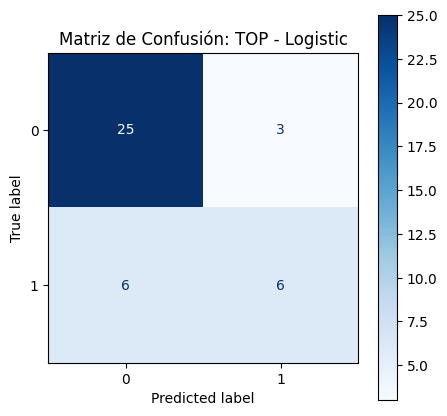


===== DATASET: BAL | MODEL: RF =====

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89        28
           1       0.86      0.50      0.63        12

    accuracy                           0.82        40
   macro avg       0.84      0.73      0.76        40
weighted avg       0.83      0.82      0.81        40



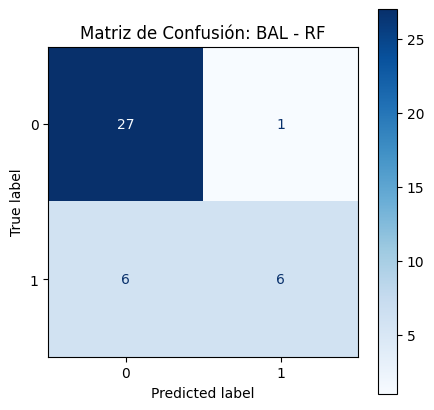


===== DATASET: FULL | MODEL: RF =====

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.96      0.89        28
           1       0.86      0.50      0.63        12

    accuracy                           0.82        40
   macro avg       0.84      0.73      0.76        40
weighted avg       0.83      0.82      0.81        40



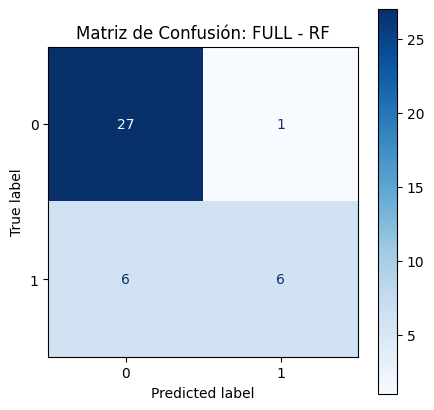

In [40]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for dataset_name, model_name, pipe, params in best_cases:

    X_train, X_test = datasets[dataset_name]

    # Reentrenar con TimeSeriesSplit para coherencia metodológica
    grid = GridSearchCV(
        pipe, params, cv=tscv, scoring='roc_auc', n_jobs=-1
    )

    grid.fit(X_train, y_train)
    best_model = grid.best_estimator_

    # Predicciones de clase (0 o 1)
    y_pred = best_model.predict(X_test)

    print(
        f"\n=================================================================="
    )
    print(f"===== DATASET: {dataset_name.upper()} | MODEL: {model_name} =====")
    print(
        f"=================================================================="
    )

    # Reporte de clasificación (Precision, Recall, F1-Score)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)

    # Graficar con estilo claro
    fig, ax = plt.subplots(figsize=(5, 5))
    disp.plot(cmap=plt.cm.Blues, ax=ax)
    plt.title(f"Matriz de Confusión: {dataset_name.upper()} - {model_name}")
    plt.grid(False)
    plt.show()

In [ ]:
# IMPORTACIONES

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# CONFIGURACIÓN

tscv = TimeSeriesSplit(n_splits=3)

# Diccionarios para guardar modelos y probabilidades

trained_models = {}
oof_probabilities = {}
best_thresholds = {}

# Listas para almacenar resultados

results_threshold = []
sensitivity_results = []

# Predicciones producidas por cada fold
fold_predictions = []

# Predicciones para cada threshold
threshold_predictions = []

# PASO 1: BÚSQUEDA DE HIPERPARÁMETROS + PROBABILIDADES OOF

for dataset_name, model_name, pipe, params in best_cases:

    # Obtener los datos correspondientes al dataset

    X_train, X_test = datasets[dataset_name]

    # 1.1 SELECCIÓN DE HIPERPARÁMETROS MEDIANTE VALIDACIÓN TEMPORAL

    grid = GridSearchCV(
        pipe,
        params,
        cv=tscv,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # Mejor modelo encontrado
    best_model = grid.best_estimator_

    # Guardar el mejor modelo
    trained_models[(dataset_name, model_name)] = best_model

    print("=" * 70)
    print(f"DATASET: {dataset_name.upper()} | MODELO: {model_name}")
    print("Mejores hiperparámetros:")
    print(grid.best_params_)
    print(f"ROC-AUC CV: {grid.best_score_:.4f}")

    # 1.2 GENERACIÓN DE PROBABILIDADES OUT-OF-FOLD (OOF)
    # Cada observación de validación es predicha por un modelo que no utilizó
    # dicha observación durante el entrenamiento.
    # Estas probabilidades se utilizarán posteriormente para estudiar el
    # comportamiento del threshold sin utilizar el conjunto de test.

    oof_probs = np.full(len(X_train), np.nan)

    # Recorrido de los folds temporales

    for fold, (train_idx, val_idx) in enumerate(
        tscv.split(X_train),
        start=1
    ):

        # Datos de entrenamiento del fold
        X_tr = X_train.iloc[train_idx]
        y_tr = y_train.iloc[train_idx]

        # Datos de validación del fold
        X_val = X_train.iloc[val_idx]
        y_val = y_train.iloc[val_idx]

        # Clonar el pipeline original

        model_fold = clone(pipe)

        # Utilizar los mejores hiperparámetros encontrados
        model_fold.set_params(**grid.best_params_)

        # Entrenamiento exclusivamente con el segmento temporal anterior

        model_fold.fit(X_tr, y_tr)

        # Obtener probabilidades para la clase 1 = Podio

        fold_probs = model_fold.predict_proba(X_val)[:, 1]

        # Guardar probabilidades OOF

        oof_probs[val_idx] = fold_probs

        # Guardar información detallada de cada predicción

        for idx, probability, true_value in zip(
            val_idx,
            fold_probs,
            y_val
        ):

            fold_predictions.append({
                "dataset": dataset_name,
                "model": model_name,
                "fold": fold,
                "index": idx,
                "y_true": true_value,
                "probability": probability
            })

    # Guardar todas las probabilidades OOF del modelo

    oof_probabilities[(dataset_name, model_name)] = oof_probs

    # PASO 2: PREPARACIÓN DE DATOS OOF PARA EL ANÁLISIS DEL THRESHOLD
    valid = ~np.isnan(oof_probs)

    # Índices que poseen predicción OOF
    valid_indices = np.where(valid)[0]

    # Valores reales
    y_oof = y_train.iloc[valid_indices].to_numpy()

    # Probabilidades OOF
    p_oof = oof_probs[valid]


    # PASO 2.1: ANÁLISIS DE SENSIBILIDAD DEL THRESHOLD

    # Thresholds candidatos
    thresholds = np.linspace(0.05, 0.95, 100)

    # Niveles mínimos de recall exigidos para la clase 0
    recall0_targets = [
        0.60,
        0.70,
        0.75,
        0.80,
        0.85,
        0.90
    ]

    results_model = []

    # Evaluar cada threshold

    for t in thresholds:

        # Regla de decisión:
        # p >= t  -> Podio
        # p <  t  -> No Podio
        y_pred_t = (p_oof >= t).astype(int)

        # Métricas

        recall_1 = recall_score(
            y_oof,
            y_pred_t,
            pos_label=1,
            zero_division=0
        )

        recall_0 = recall_score(
            y_oof,
            y_pred_t,
            pos_label=0,
            zero_division=0
        )

        precision_1 = precision_score(
            y_oof,
            y_pred_t,
            pos_label=1,
            zero_division=0
        )

        f1_1 = f1_score(
            y_oof,
            y_pred_t,
            pos_label=1,
            zero_division=0
        )

        # Guardar resultados del threshold

        results_model.append({

            "dataset": dataset_name,

            "model": model_name,

            "threshold": t,

            "recall_0": recall_0,

            "recall_1": recall_1,

            "precision_1": precision_1,

            "f1_1": f1_1
        })

        # Guardar predicción individual para este threshold
        #
        # Esto será útil posteriormente para analizar:
        #
        # - comportamiento del threshold
        # - errores
        # - sesgo
        # - estabilidad
        # - decisiones binarias

        for idx, probability, true_value, prediction in zip(
            valid_indices,
            p_oof,
            y_oof,
            y_pred_t
        ):

            threshold_predictions.append({

                "dataset": dataset_name,

                "model": model_name,

                "index": idx,

                "threshold": t,

                "y_true": true_value,

                "probability": probability,

                "prediction": prediction
            })

    # PASO 2.2: DATAFRAME DE THRESHOLDS

    df_model_th = pd.DataFrame(results_model)

    results_threshold.extend(results_model)
    # PASO 2.3: ANÁLISIS DE SENSIBILIDAD

    for target in recall0_targets:

        # Thresholds que cumplen la restricción de recall de clase 0

        candidates = df_model_th[
            df_model_th["recall_0"] >= target
        ]

        # Si no existe ningún threshold válido
        if len(candidates) == 0:

            print(
                f"Advertencia: {dataset_name} + {model_name}: "
                f"no existe threshold con Recall_0 >= {target:.0%}"
            )

            continue

        # Entre los thresholds válidos se selecciona aquel que maximiza F1
        # En caso de empate se utiliza Recall_1 como segundo criterio.

        best_row = (
            candidates
            .sort_values(
                ["f1_1", "recall_1"],
                ascending=[False, False]
            )
            .iloc[0]
        )

        # Guardar resultado
        sensitivity_results.append({

            "dataset": dataset_name,

            "model": model_name,

            "recall0_target": target,

            "threshold": best_row["threshold"],

            "recall_0": best_row["recall_0"],

            "recall_1": best_row["recall_1"],

            "precision_1": best_row["precision_1"],

            "f1_1": best_row["f1_1"]
        })


# PASO 3: CREACIÓN DE DATAFRAMES FINALES
# 3.1 Resultados generales de threshold

df_threshold = pd.DataFrame(results_threshold)

# 3.2 Resultados del análisis de sensibilidad

df_sensitivity = pd.DataFrame(sensitivity_results)

# 3.3 Predicciones por fold
df_fold_predictions = pd.DataFrame(fold_predictions)

# 3.4 Predicciones para cada threshold

df_threshold_predictions = pd.DataFrame(threshold_predictions)

# PASO 4: VARIABLES DERIVADAS PARA EL ANÁLISIS POSTERIOR
# Error de probabilidad
# error = valor observado - probabilidad estimada
# Será útil posteriormente para estudiar sesgo/calibración.

df_fold_predictions["error_probability"] = (
    df_fold_predictions["y_true"]
    - df_fold_predictions["probability"]
)

# Error absoluto de probabilidad

df_fold_predictions["absolute_error_probability"] = (
    df_fold_predictions["error_probability"].abs()
)

# Error cuadrático de probabilidad

df_fold_predictions["squared_error_probability"] = (
    df_fold_predictions["error_probability"] ** 2
)

# Error de la decisión binaria para cada threshold

df_threshold_predictions["error_binary"] = (
    df_threshold_predictions["y_true"]
    - df_threshold_predictions["prediction"]
)

# Error cuadrático de la decisión binaria

df_threshold_predictions["squared_error_binary"] = (
    df_threshold_predictions["error_binary"] ** 2
)

# PASO 5: MOSTRAR RESULTADOS

print("\n" + "=" * 70)
print("ANÁLISIS DE SENSIBILIDAD DEL THRESHOLD")
print("=" * 70)

display(df_sensitivity)


print("\n" + "=" * 70)
print("PREDICCIONES OOF POR FOLD")
print("=" * 70)

display(df_fold_predictions.head())


print("\n" + "=" * 70)
print("PREDICCIONES PARA LOS THRESHOLDS")
print("=" * 70)

display(df_threshold_predictions.head())


print("\n" + "=" * 70)
print("RESULTADOS COMPLETOS DE THRESHOLD")
print("=" * 70)

display(df_threshold.head())

DATASET: TOP | MODELO: Logistic
Mejores hiperparámetros:
{'model__C': 10, 'model__penalty': 'l2'}
ROC-AUC CV: 0.7568
DATASET: BAL | MODELO: RF
Mejores hiperparámetros:
{'model__max_depth': 3, 'model__n_estimators': 100}
ROC-AUC CV: 0.7570
DATASET: FULL | MODELO: RF
Mejores hiperparámetros:
{'model__max_depth': 3, 'model__n_estimators': 200}
ROC-AUC CV: 0.7377

ANÁLISIS DE SENSIBILIDAD DEL THRESHOLD


,dataset,model,recall0_target,threshold,recall_0,recall_1,precision_1,f1_1
0,top,Logistic,0.60,0.368182,0.615385,0.818182,0.473684,0.600000
1,top,Logistic,0.70,0.468182,0.717949,0.696970,0.511111,0.589744
2,top,Logistic,0.75,0.495455,0.756410,0.575758,0.500000,0.535211
3,top,Logistic,0.80,0.568182,0.820513,0.515152,0.548387,0.531250
4,top,Logistic,0.85,0.677273,0.858974,0.424242,0.560000,0.482759
5,top,Logistic,0.90,0.768182,0.910256,0.333333,0.611111,0.431373
6,bal,RF,0.60,0.386364,0.756410,0.666667,0.536585,0.594595
7,bal,RF,0.70,0.386364,0.756410,0.666667,0.536585,0.594595
8,bal,RF,0.75,0.386364,0.756410,0.666667,0.536585,0.594595
9,bal,RF,0.80,0.450000,0.820513,0.515152,0.548387,0.531250



PREDICCIONES OOF POR FOLD


,dataset,model,fold,index,y_true,probability,error_probability,absolute_error_probability,squared_error_probability
0,top,Logistic,1,39,0,0.046774,-0.046774,0.046774,2.187812e-03
1,top,Logistic,1,40,1,0.999997,0.000003,0.000003,9.538690e-12
2,top,Logistic,1,41,1,0.150772,0.849228,0.849228,7.211884e-01
3,top,Logistic,1,42,1,0.995116,0.004884,0.004884,2.385157e-05
4,top,Logistic,1,43,0,0.291145,-0.291145,0.291145,8.476533e-02



PREDICCIONES PARA LOS THRESHOLDS


,dataset,model,index,threshold,y_true,probability,prediction,error_binary,squared_error_binary
0,top,Logistic,39,0.05,0,0.046774,0,0,0
1,top,Logistic,40,0.05,1,0.999997,1,0,0
2,top,Logistic,41,0.05,1,0.150772,1,0,0
3,top,Logistic,42,0.05,1,0.995116,1,0,0
4,top,Logistic,43,0.05,0,0.291145,1,-1,1



RESULTADOS COMPLETOS DE THRESHOLD


,dataset,model,threshold,recall_0,recall_1,precision_1,f1_1
0,top,Logistic,0.050000,0.025641,1.000000,0.302752,0.464789
1,top,Logistic,0.059091,0.038462,1.000000,0.305556,0.468085
2,top,Logistic,0.068182,0.064103,1.000000,0.311321,0.474820
3,top,Logistic,0.077273,0.064103,0.969697,0.304762,0.463768
4,top,Logistic,0.086364,0.076923,0.969697,0.307692,0.467153


Para el análisis del sesgo y la varianza se utilizaron las probabilidades de predicción generadas mediante múltiples modelos entrenados sobre diferentes muestras temporales del conjunto de entrenamiento. Para cada observación del conjunto de evaluación se obtuvieron varias predicciones de probabilidad, lo que permitió estudiar la variabilidad de las decisiones ante diferentes ajustes del modelo. Posteriormente, para cada valor del *threshold* $(t)$, las probabilidades se transformaron en decisiones binarias mediante la regla $(\hat{Y}_t=I(\hat{p}\geq t))$. A partir de estas decisiones se calculó, para cada observación, la predicción media y su varianza. El sesgo se cuantificó mediante el error cuadrático entre la predicción media y el valor real, mientras que la varianza se obtuvo como la media de las desviaciones cuadráticas de las decisiones respecto a su predicción media. Finalmente, estos valores se promediaron sobre las observaciones evaluadas para obtener una medida global de $(sesgo^2(t))$ y $(Varianza(t))$ para cada *threshold*. Esta metodología permitió analizar cómo la modificación del umbral de decisión afecta simultáneamente el sesgo y la variabilidad de las decisiones del modelo.


In [ ]:
# ANÁLISIS DE SESGO Y VARIANZA
# GENERACIÓN DE MÚLTIPLES MODELOS SOBRE MUESTRAS TEMPORALES

import numpy as np
import pandas as pd

from sklearn.base import clone

# CONFIGURACIÓN

N_REPETICIONES = 30

# Resultados de las predicciones repetidas
repeated_predictions = []

# CONJUNTO DE EVALUACIÓN
# Utilizamos exclusivamente el conjunto de entrenamiento.
# El test 2021-2024 NO se utiliza para seleccionar threshold ni para calcular sesgo/varianza.
# Para mantener la estructura temporal, utilizamos las últimas observaciones del conjunto de entrenamiento como conjunto común de evaluación.

EVAL_FRACTION = 0.25

# RECORRIDO DE DATASETS Y MODELOS

for dataset_name, model_name, pipe, params in best_cases:

    X_train, X_test = datasets[dataset_name]

    # Obtener mejores hiperparámetros almacenados

    best_model = trained_models[(dataset_name, model_name)]

    best_params = best_model.get_params()

    # Determinar tamaño del conjunto de evaluación

    n = len(X_train)

    n_eval = int(np.ceil(n * EVAL_FRACTION))

    eval_start = n - n_eval

    # Conjunto común de evaluación

    X_eval = X_train.iloc[eval_start:]
    y_eval = y_train.iloc[eval_start:]

    # Parte histórica disponible para entrenamiento

    X_base = X_train.iloc[:eval_start]
    y_base = y_train.iloc[:eval_start]


    print("=" * 70)
    print(f"DATASET: {dataset_name.upper()} | MODELO: {model_name}")
    print(f"Observaciones para evaluación: {len(X_eval)}")
    print(f"Observaciones disponibles para entrenamiento: {len(X_base)}")

    # GENERAR MÚLTIPLES MODELOS

    for repetition in range(N_REPETICIONES):

        # Generador aleatorio reproducible

        rng = np.random.default_rng(1000 + repetition)

        # Muestreo con reemplazo de BLOQUES temporales
        # Se conserva la estructura temporal mediante bloques consecutivos.

        block_size = 5

        blocks = [
            np.arange(i, min(i + block_size, len(X_base)))
            for i in range(0, len(X_base), block_size)
        ]


        # Seleccionar bloques con reemplazo
        selected_blocks = rng.choice(
            len(blocks),
            size=len(blocks),
            replace=True
        )


        # Construir índices de entrenamiento
        train_indices = np.concatenate(
            [blocks[i] for i in selected_blocks]
        )


        X_rep = X_base.iloc[train_indices]
        y_rep = y_base.iloc[train_indices]

        # Crear y entrenar modelo

        model_rep = clone(pipe)

        model_rep.set_params(**best_model.get_params())

        model_rep.fit(X_rep, y_rep)


        # Predicciones sobre EL MISMO conjunto de evaluación

        probabilities = model_rep.predict_proba(X_eval)[:, 1]

        # Guardar resultados

        for idx, probability, true_value in zip(
            X_eval.index,
            probabilities,
            y_eval
        ):

            repeated_predictions.append({

                "dataset": dataset_name,

                "model": model_name,

                "repetition": repetition,

                "index": idx,

                "y_true": true_value,

                "probability": probability
            })

# DATAFRAME

df_repeated_predictions = pd.DataFrame(
    repeated_predictions
)

# COMPROBACIÓN

print("\n" + "=" * 70)
print("PREDICCIONES REPETIDAS")
print("=" * 70)

display(df_repeated_predictions.head())

print(
    f"\nNúmero total de predicciones almacenadas: "
    f"{len(df_repeated_predictions)}"
)


DATASET: TOP | MODELO: Logistic
Observaciones para evaluación: 38
Observaciones disponibles para entrenamiento: 112
DATASET: BAL | MODELO: RF
Observaciones para evaluación: 38
Observaciones disponibles para entrenamiento: 112
DATASET: FULL | MODELO: RF
Observaciones para evaluación: 38
Observaciones disponibles para entrenamiento: 112

PREDICCIONES REPETIDAS


,dataset,model,repetition,index,y_true,probability
0,top,Logistic,0,112,1,0.502646
1,top,Logistic,0,113,0,0.036373
2,top,Logistic,0,114,0,0.105012
3,top,Logistic,0,115,0,0.096627
4,top,Logistic,0,116,0,0.025369



Número total de predicciones almacenadas: 3420


In [ ]:
# CÁLCULO DE SESGO Y VARIANZA EN FUNCIÓN DEL THRESHOLD

threshold_bias_variance = []

thresholds_bv = np.linspace(0.05, 0.95, 100)

# RECORRER DATASET Y MODELO

for (dataset_name, model_name), df_group in (
    df_repeated_predictions
    .groupby(["dataset", "model"])
):

    # Recorrer thresholds

    for t in thresholds_bv:

        # Aplicar threshold a todas las predicciones

        predictions = (
            df_group["probability"] >= t
        ).astype(int)


        df_temp = df_group.copy()

        df_temp["prediction"] = predictions

        # Media de la predicción para cada observación

        mean_prediction = (
            df_temp
            .groupby("index")["prediction"]
            .mean()
            .rename("mean_prediction")
        )

        # Varianza de la predicción para cada observación

        prediction_variance = (
            df_temp
            .groupby("index")["prediction"]
            .var(ddof=0)
            .rename("prediction_variance")
        )

        # Valor verdadero de cada observación

        true_values = (
            df_temp
            .groupby("index")["y_true"]
            .first()
            .rename("y_true")
        )

        # Unir resultados

        summary = pd.concat(
            [
                mean_prediction,
                prediction_variance,
                true_values
            ],
            axis=1
        )

        # SESGO CUADRÁTICO
        summary["bias_squared"] = (
            summary["mean_prediction"]
            - summary["y_true"]
        ) ** 2

        # ERROR CUADRÁTICO ESPERADO

        summary["squared_error"] = (
            df_temp
            .assign(
                squared_error=lambda d:
                (d["prediction"] - d["y_true"]) ** 2
            )
            .groupby("index")["squared_error"]
            .mean()
        )

        # Promedios sobre todas las observaciones

        threshold_bias_variance.append({

            "dataset": dataset_name,

            "model": model_name,

            "threshold": t,

            "bias_squared":
                summary["bias_squared"].mean(),

            "variance":
                summary["prediction_variance"].mean(),

            "squared_error":
                summary["squared_error"].mean()
        })

# DATAFRAME FINAL

df_bias_variance = pd.DataFrame(
    threshold_bias_variance
)

# COMPROBACIÓN

display(
    df_bias_variance.head()
)

,dataset,model,threshold,bias_squared,variance,squared_error
0,bal,RF,0.050000,0.728246,0.005088,0.733333
1,bal,RF,0.059091,0.724854,0.006725,0.731579
2,bal,RF,0.068182,0.721404,0.008421,0.729825
3,bal,RF,0.077273,0.711959,0.013480,0.725439
4,bal,RF,0.086364,0.702047,0.019006,0.721053


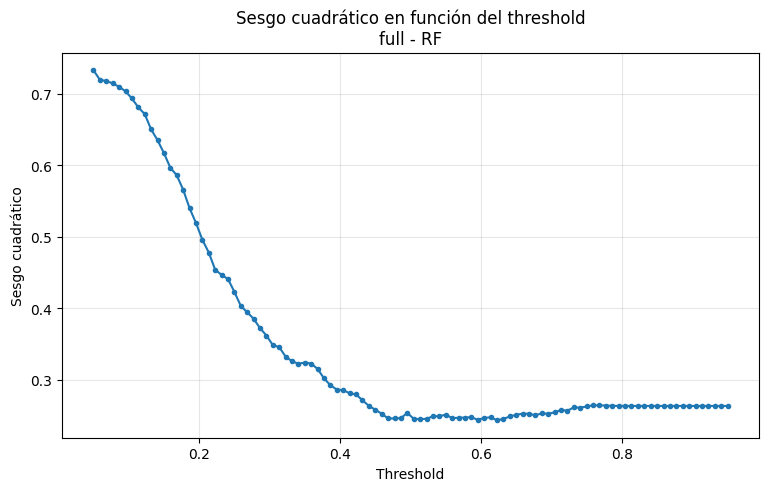

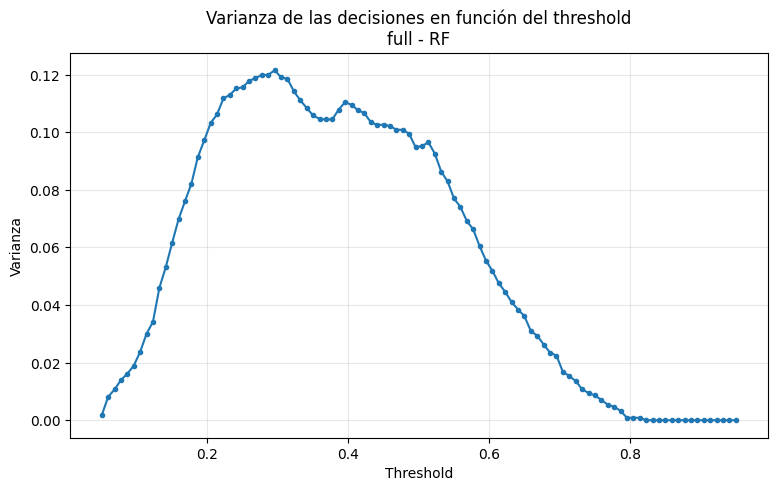

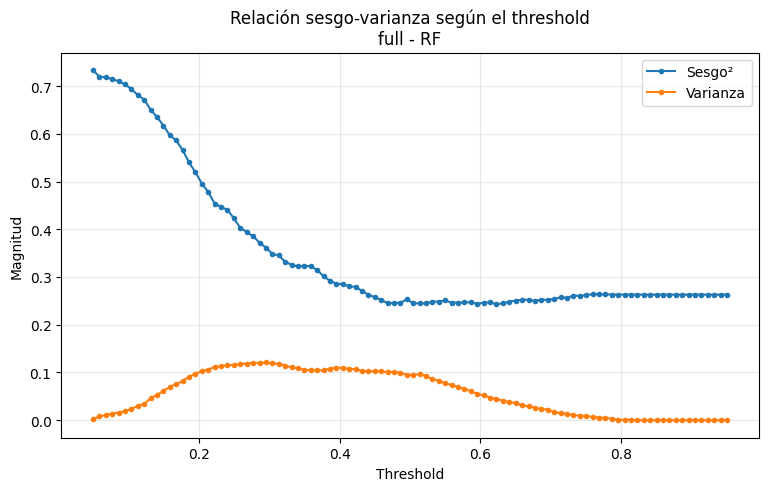

In [44]:
import matplotlib.pyplot as plt


# Seleccionar un caso
dataset_selected = "full"
model_selected = "RF"


df_plot = df_bias_variance[
    (df_bias_variance["dataset"] == dataset_selected) &
    (df_bias_variance["model"] == model_selected)
]


plt.figure(figsize=(9, 5))

plt.plot(
    df_plot["threshold"],
    df_plot["bias_squared"],
    marker="o",
    markersize=3
)

plt.xlabel("Threshold")
plt.ylabel("Sesgo cuadrático")
plt.title(
    f"Sesgo cuadrático en función del threshold\n"
    f"{dataset_selected} - {model_selected}"
)

plt.grid(True, alpha=0.3)

plt.show()
plt.figure(figsize=(9, 5))

plt.plot(
    df_plot["threshold"],
    df_plot["variance"],
    marker="o",
    markersize=3
)

plt.xlabel("Threshold")
plt.ylabel("Varianza")
plt.title(
    f"Varianza de las decisiones en función del threshold\n"
    f"{dataset_selected} - {model_selected}"
)

plt.grid(True, alpha=0.3)

plt.show()
plt.figure(figsize=(9, 5))

plt.plot(
    df_plot["threshold"],
    df_plot["bias_squared"],
    marker="o",
    markersize=3,
    label="Sesgo²"
)

plt.plot(
    df_plot["threshold"],
    df_plot["variance"],
    marker="o",
    markersize=3,
    label="Varianza"
)

plt.xlabel("Threshold")
plt.ylabel("Magnitud")
plt.title(
    f"Relación sesgo-varianza según el threshold\n"
    f"{dataset_selected} - {model_selected}"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

El análisis del sesgo cuadrático en función del *threshold* permite observar cómo cambia la discrepancia entre la decisión media de los modelos y la clase observada cuando se modifica el umbral utilizado para distinguir entre ciclistas con y sin podio. La varianza de las decisiones en función del *threshold* representa la estabilidad de las clasificaciones obtenidas a partir de los diferentes modelos. Valores elevados indican que pequeñas modificaciones en el modelo pueden producir decisiones diferentes para determinadas observaciones, mientras que valores reducidos reflejan mayor estabilidad. La relación sesgo-varianza permite estudiar conjuntamente ambos comportamientos y observar cómo la elección del *threshold* modifica el equilibrio entre precisión de la decisión media y estabilidad de las predicciones. En consecuencia, el análisis no se limita a identificar un único umbral, sino que permite caracterizar el comportamiento del modelo a lo largo de diferentes reglas de decisión.


In [45]:
df_bias_variance["bias_plus_variance"] = (
    df_bias_variance["bias_squared"]
    + df_bias_variance["variance"]
)

df_bias_variance["difference"] = (
    df_bias_variance["squared_error"]
    - df_bias_variance["bias_plus_variance"]
)


display(
    df_bias_variance[
        [
            "dataset",
            "model",
            "threshold",
            "bias_squared",
            "variance",
            "squared_error",
            "bias_plus_variance",
            "difference"
        ]
    ].head(20)
)

,dataset,model,threshold,bias_squared,variance,squared_error,bias_plus_variance,difference
0,bal,RF,0.050000,0.728246,0.005088,0.733333,0.733333,-1.110223e-16
1,bal,RF,0.059091,0.724854,0.006725,0.731579,0.731579,0.000000e+00
2,bal,RF,0.068182,0.721404,0.008421,0.729825,0.729825,0.000000e+00
3,bal,RF,0.077273,0.711959,0.013480,0.725439,0.725439,0.000000e+00
4,bal,RF,0.086364,0.702047,0.019006,0.721053,0.721053,0.000000e+00
5,bal,RF,0.095455,0.698772,0.020526,0.719298,0.719298,-1.110223e-16
6,bal,RF,0.104545,0.682895,0.028509,0.711404,0.711404,-1.110223e-16
7,bal,RF,0.113636,0.671930,0.033333,0.705263,0.705263,0.000000e+00
8,bal,RF,0.122727,0.658187,0.041813,0.700000,0.700000,0.000000e+00
9,bal,RF,0.131818,0.644912,0.048070,0.692982,0.692982,-2.220446e-16


In [ ]:
# PASO 3: SELECCIÓN DEL THRESHOLD FINAL SEGÚN EL CRITERIO DE SENSIBILIDAD

df_sensitivity = pd.DataFrame(sensitivity_results)

# Criterio elegido:
# maximizar F1 de la clase 1 (Podio)
# sujeto a Recall de la clase 0 >= 75%

target_recall_0 = 0.75

candidates = df_sensitivity[
    df_sensitivity["recall0_target"] == target_recall_0
].copy()

best_per_model = (
    candidates
    .sort_values(
        ["f1_1", "recall_1"],
        ascending=[False, False]
    )
    .groupby(["dataset", "model"])
    .first()
    .reset_index()
)

print("\n")
print("=" * 70)
print("THRESHOLDS FINALES SELECCIONADOS CON DATOS OOF")
print("=" * 70)

print(
    best_per_model[
        [
            "dataset",
            "model",
            "recall0_target",
            "threshold",
            "recall_0",
            "recall_1",
            "precision_1",
            "f1_1"
        ]
    ].to_string(index=False)
)



THRESHOLDS FINALES SELECCIONADOS CON DATOS OOF
dataset    model  recall0_target  threshold  recall_0  recall_1  precision_1     f1_1
    bal       RF            0.75   0.386364  0.756410  0.666667     0.536585 0.594595
   full       RF            0.75   0.431818  0.794872  0.575758     0.542857 0.558824
    top Logistic            0.75   0.495455  0.756410  0.575758     0.500000 0.535211


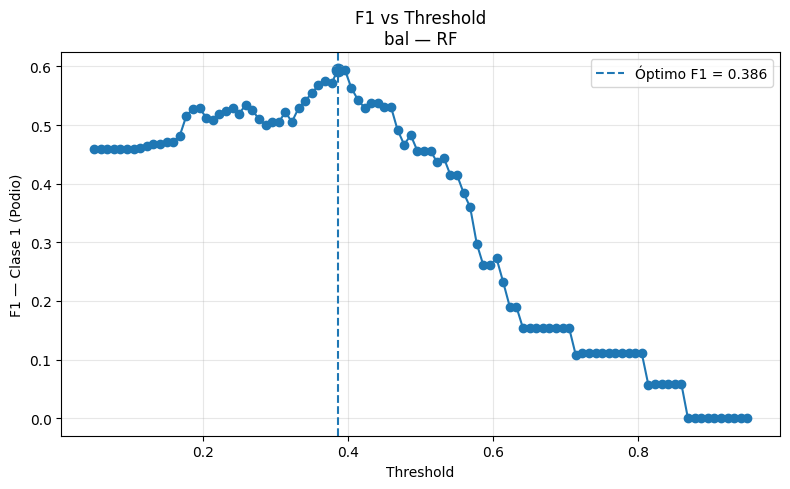

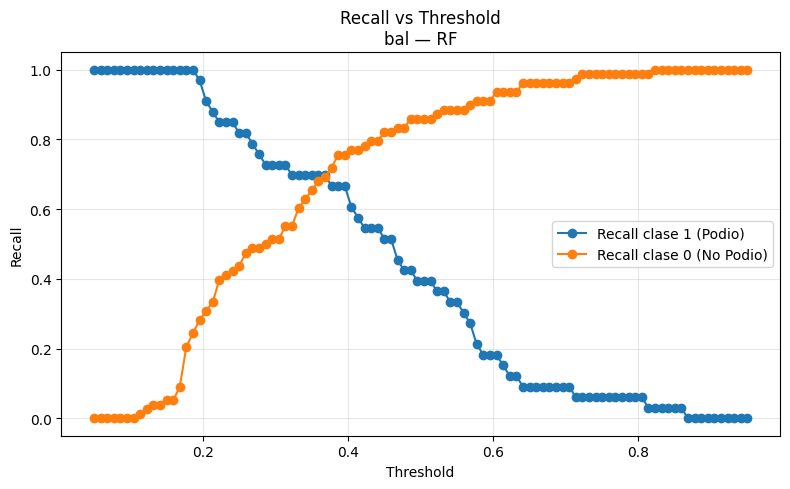

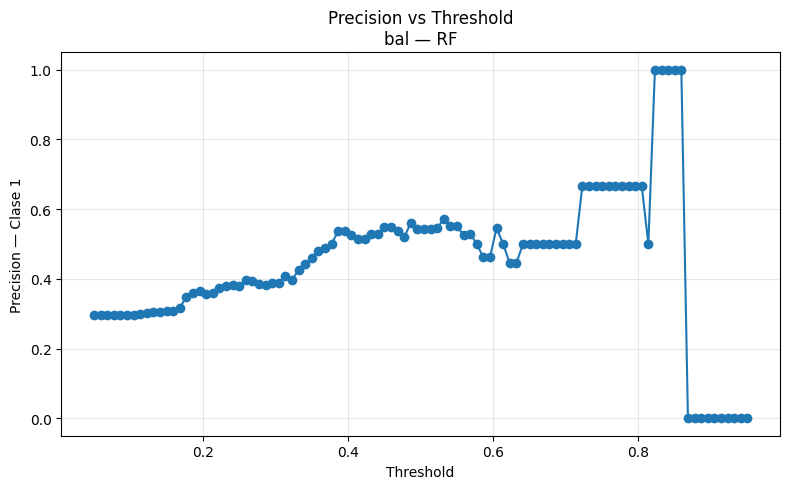

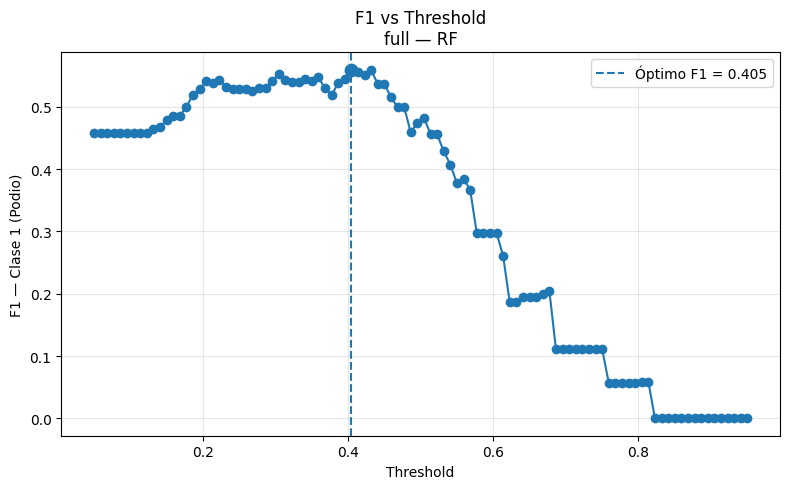

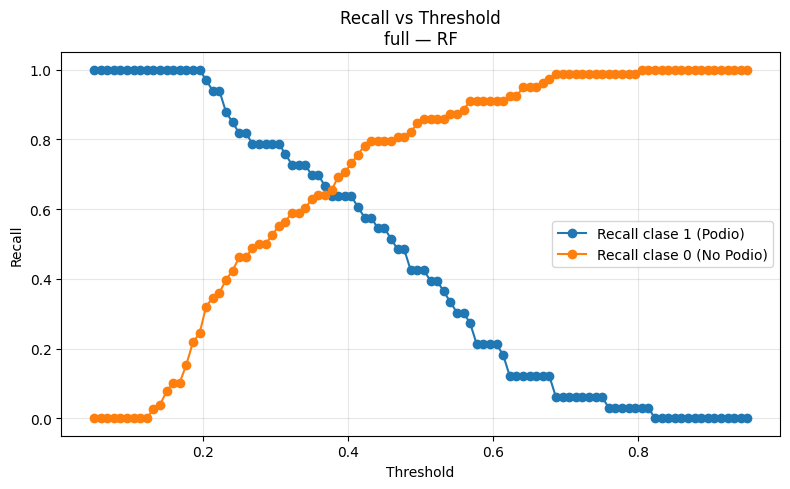

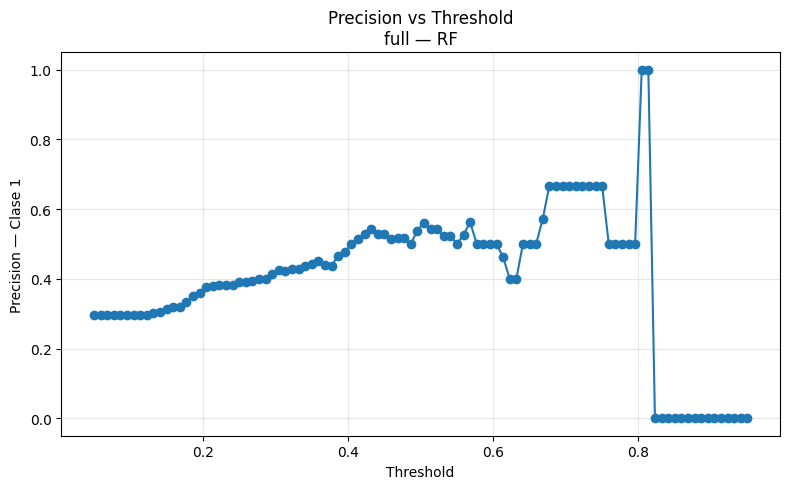

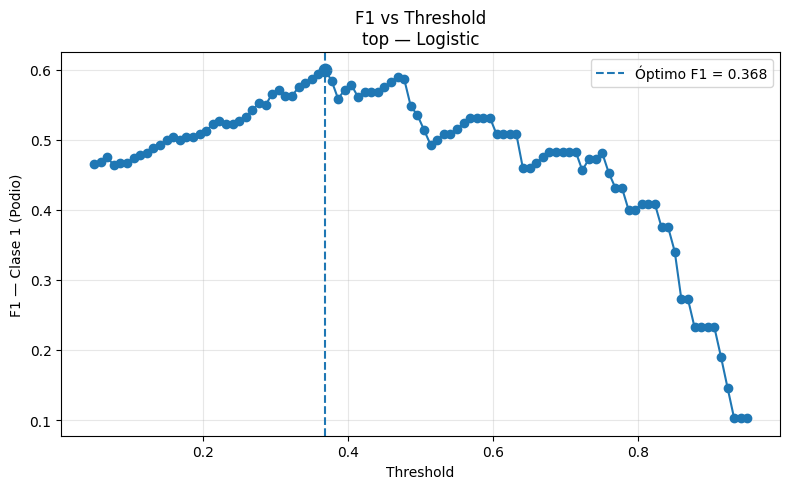

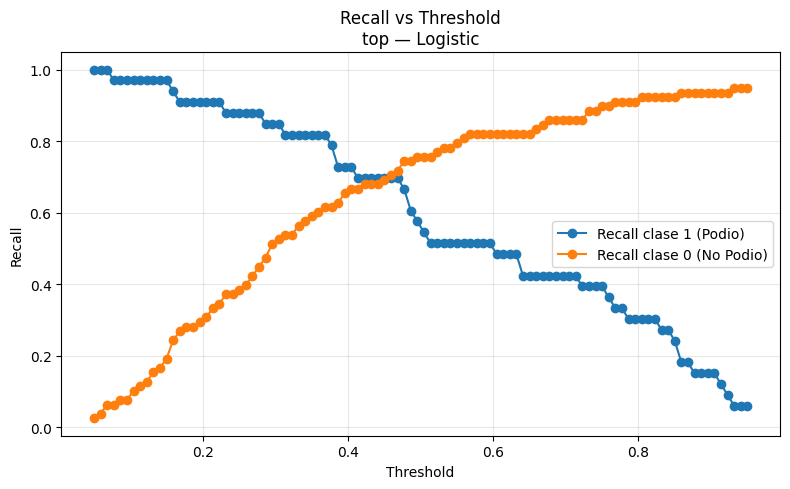

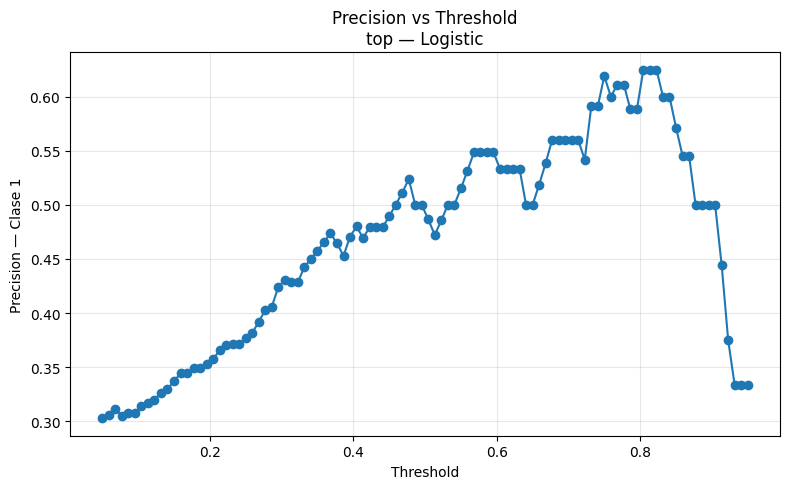

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# GRÁFICAS DEL COMPORTAMIENTO DEL THRESHOLD

for (dataset_name, model_name), df_group in (
    pd.DataFrame(results_threshold)
    .groupby(["dataset", "model"])
):

    df_group = df_group.sort_values("threshold")

    # 1. F1 vs Threshold

    plt.figure(figsize=(8, 5))

    plt.plot(
        df_group["threshold"],
        df_group["f1_1"],
        marker="o"
    )

    # Threshold que maximiza F1
    best_idx = df_group["f1_1"].idxmax()
    best_t = df_group.loc[best_idx, "threshold"]
    best_f1 = df_group.loc[best_idx, "f1_1"]

    plt.axvline(
        best_t,
        linestyle="--",
        label=f"Óptimo F1 = {best_t:.3f}"
    )

    plt.scatter(
        best_t,
        best_f1,
        s=80
    )

    plt.xlabel("Threshold")
    plt.ylabel("F1 — Clase 1 (Podio)")
    plt.title(
        f"F1 vs Threshold\n"
        f"{dataset_name} — {model_name}"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 2. Recall de ambas clases

    plt.figure(figsize=(8, 5))

    plt.plot(
        df_group["threshold"],
        df_group["recall_1"],
        marker="o",
        label="Recall clase 1 (Podio)"
    )

    plt.plot(
        df_group["threshold"],
        df_group["recall_0"],
        marker="o",
        label="Recall clase 0 (No Podio)"
    )

    plt.xlabel("Threshold")
    plt.ylabel("Recall")
    plt.title(
        f"Recall vs Threshold\n"
        f"{dataset_name} — {model_name}"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 3. Precision vs Threshold

    plt.figure(figsize=(8, 5))

    plt.plot(
        df_group["threshold"],
        df_group["precision_1"],
        marker="o"
    )

    plt.xlabel("Threshold")
    plt.ylabel("Precision — Clase 1")
    plt.title(
        f"Precision vs Threshold\n"
        f"{dataset_name} — {model_name}"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Los gráficos de precisión, F1 y *recall* frente al *threshold* permiten analizar el efecto del umbral de decisión sobre las principales métricas de clasificación. La precisión de la clase positiva indica la proporción de ciclistas clasificados como candidatos a podio que efectivamente pertenecen a dicha clase, por lo que su comportamiento permite identificar el efecto del aumento del umbral sobre los falsos positivos. El *recall* de la clase positiva representa la proporción de ciclistas que realmente obtuvieron podio y fueron correctamente identificados, mostrando el efecto del umbral sobre los falsos negativos. Por su parte, el F1 combina precisión y *recall* mediante su media armónica y permite estudiar conjuntamente ambas propiedades. En general, la modificación del *threshold* produce un intercambio entre estas métricas: umbrales más bajos tienden a generar más predicciones positivas, mientras que umbrales más altos hacen más restrictiva la clasificación como podio. Los gráficos permiten visualizar este comportamiento y determinar las regiones en las que las métricas presentan un desempeño favorable.


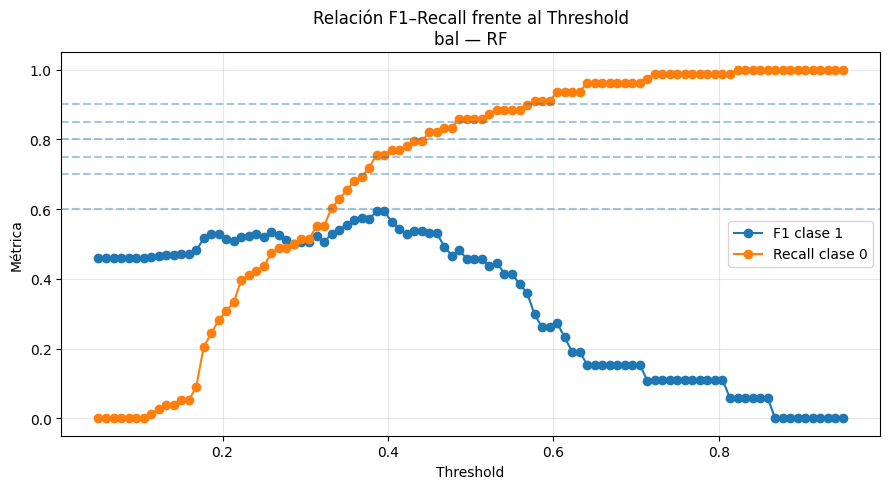

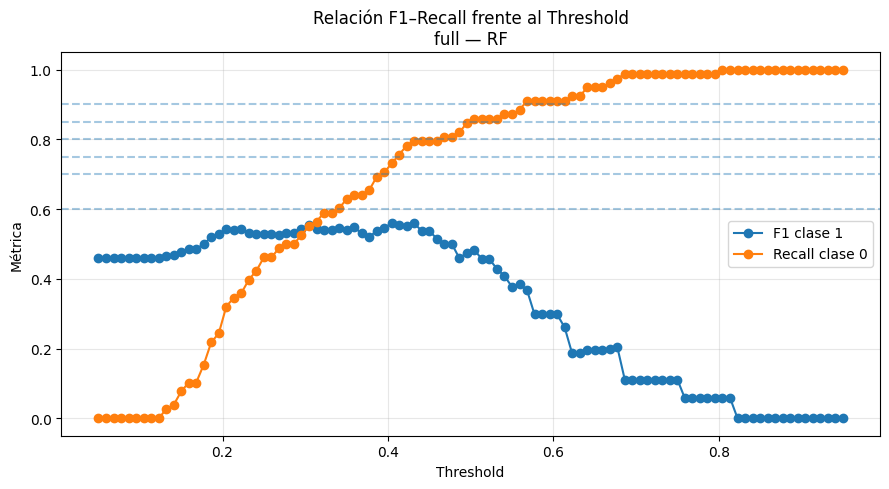

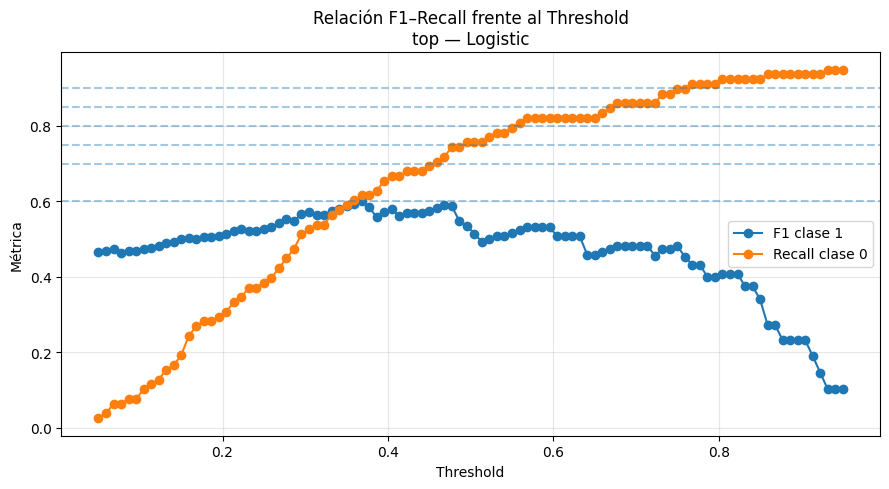

In [48]:
for (dataset_name, model_name), df_group in (
    pd.DataFrame(results_threshold)
    .groupby(["dataset", "model"])
):

    df_group = df_group.sort_values("threshold")

    plt.figure(figsize=(9, 5))

    plt.plot(
        df_group["threshold"],
        df_group["f1_1"],
        marker="o",
        label="F1 clase 1"
    )

    plt.plot(
        df_group["threshold"],
        df_group["recall_0"],
        marker="o",
        label="Recall clase 0"
    )

    for target in recall0_targets:
        plt.axhline(
            target,
            linestyle="--",
            alpha=0.4
        )

    plt.xlabel("Threshold")
    plt.ylabel("Métrica")
    plt.title(
        f"Relación F1–Recall frente al Threshold\n"
        f"{dataset_name} — {model_name}"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

El análisis del compromiso entre F1 y *recall* frente al *threshold* permite estudiar de manera conjunta la capacidad del modelo para identificar correctamente los ciclistas que obtienen un puesto de podio y el equilibrio entre precisión y recuperación de dicha clase. Al modificar el umbral, el número de observaciones clasificadas como podio cambia, afectando simultáneamente el *recall* y la precisión, y, por consiguiente, el valor del F1. La representación conjunta de estas métricas permite identificar cómo evoluciona este compromiso a medida que la regla de decisión se hace más o menos restrictiva. Este análisis resulta especialmente relevante cuando no se busca únicamente maximizar una métrica aislada, sino evaluar el comportamiento del modelo bajo diferentes niveles de sensibilidad hacia la clase positiva.


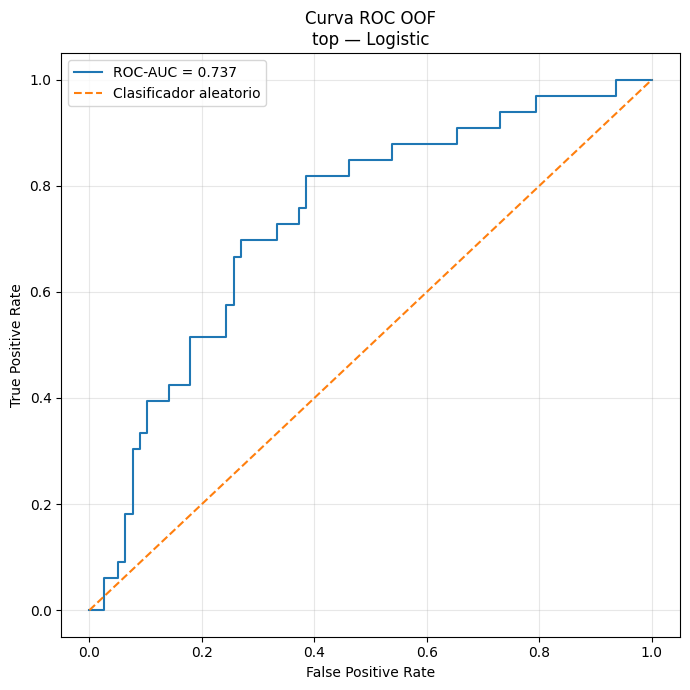

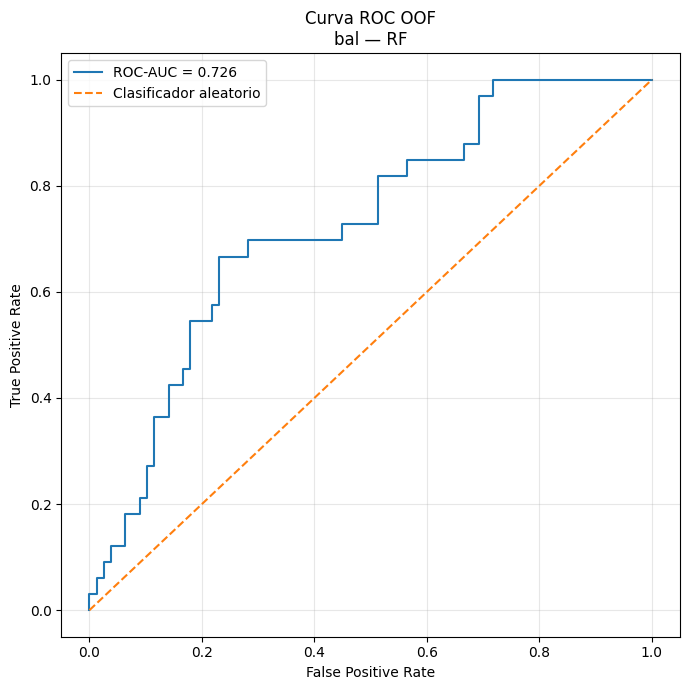

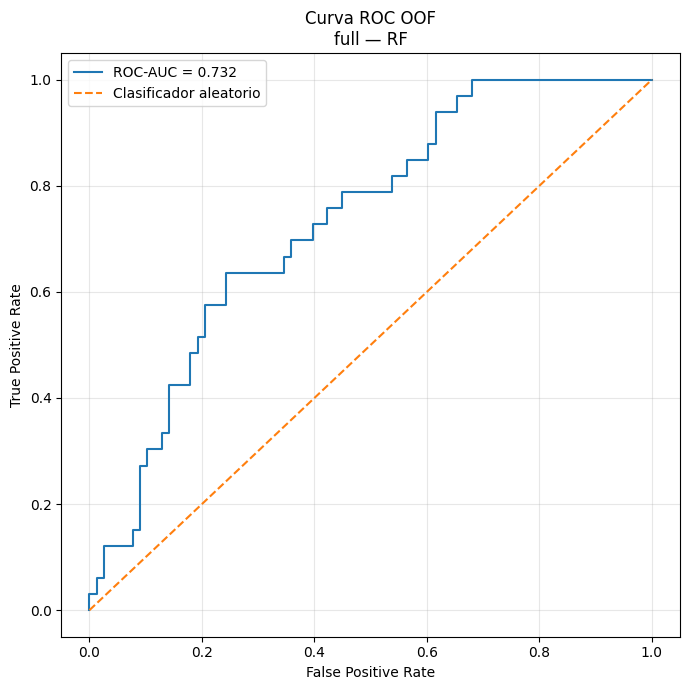

In [49]:
from sklearn.metrics import roc_curve, roc_auc_score

for (dataset_name, model_name), oof_probs in oof_probabilities.items():

    valid = ~np.isnan(oof_probs)

    y_oof = y_train.iloc[np.where(valid)[0]]
    p_oof = oof_probs[valid]

    fpr, tpr, thresholds_roc = roc_curve(
        y_oof,
        p_oof
    )

    auc = roc_auc_score(
        y_oof,
        p_oof
    )

    plt.figure(figsize=(7, 7))

    plt.plot(
        fpr,
        tpr,
        label=f"ROC-AUC = {auc:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Clasificador aleatorio"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(
        f"Curva ROC OOF\n"
        f"{dataset_name} — {model_name}"
    )

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

La curva ROC OOF se construyó a partir de las probabilidades obtenidas mediante predicciones *Out-of-Fold*, de modo que cada observación fue evaluada por un modelo que no había utilizado dicha observación durante su entrenamiento. La curva representa la relación entre la tasa de verdaderos positivos (*True Positive Rate*, TPR) y la tasa de falsos positivos (*False Positive Rate*, FPR) para los diferentes valores posibles del *threshold*. De esta manera, cada punto de la curva corresponde a una regla de decisión diferente aplicada sobre las probabilidades estimadas. El área bajo la curva ROC (ROC-AUC) resume la capacidad discriminativa del modelo para distinguir entre ciclistas que alcanzan el podio y aquellos que no lo alcanzan, independientemente de un *threshold* específico. Al utilizar predicciones OOF, esta evaluación se realiza sobre observaciones que no participaron directamente en el entrenamiento del modelo que produjo cada predicción, proporcionando una estimación interna de su capacidad de discriminación durante la etapa de validación temporal.


In [ ]:
# PASO 4: EVALUACIÓN FINAL SOBRE 2021-2024
# El threshold fue seleccionado exclusivamente con datos OOF de 2006-2020.

results_test = []

for idx, row in best_per_model.iterrows():

    d_name = row["dataset"]
    m_name = row["model"]
    opt_t = row["threshold"]

    X_train, X_test = datasets[d_name]

    # Modelo entrenado utilizando 2006-2020
    best_model = trained_models[(d_name, m_name)]

    # Probabilidades sobre el conjunto TEST: 2021-2024
    y_probs_test = best_model.predict_proba(X_test)[:, 1]

    # Aplicar threshold previamente congelado
    y_pred_opt = (y_probs_test >= opt_t).astype(int)

    # Métricas finales

    precision_1 = precision_score(
        y_test,
        y_pred_opt,
        pos_label=1,
        zero_division=0
    )

    recall_1 = recall_score(
        y_test,
        y_pred_opt,
        pos_label=1,
        zero_division=0
    )

    f1_1 = f1_score(
        y_test,
        y_pred_opt,
        pos_label=1,
        zero_division=0
    )

    # Recall de la clase 0
    recall_0 = recall_score(
        y_test,
        y_pred_opt,
        pos_label=0,
        zero_division=0
    )

    results_test.append({
        "dataset": d_name,
        "model": m_name,
        "threshold": opt_t,
        "recall_0_test": recall_0,
        "precision_1_test": precision_1,
        "recall_1_test": recall_1,
        "f1_1_test": f1_1
    })

    # PASO 5: MATRIZ DE CONFUSIÓN Y REPORTE

    print("\n" + "=" * 70)
    print(
        f"DATASET: {d_name.upper()} | "
        f"MODELO: {m_name} | "
        f"THRESHOLD: {opt_t:.4f}"
    )
    print("=" * 70)

    print("\n--- MATRIZ DE CONFUSIÓN ---")

    cm = confusion_matrix(
        y_test,
        y_pred_opt
    )

    cm_df = pd.DataFrame(
        cm,
        index=[
            "Real 0 (No Podio)",
            "Real 1 (Podio)"
        ],
        columns=[
            "Pred 0",
            "Pred 1"
        ]
    )

    print(cm_df)

    print("\n--- REPORTE DE CLASIFICACIÓN ---")

    print(
        classification_report(
            y_test,
            y_pred_opt,
            target_names=[
                "No Podio (0)",
                "Podio (1)"
            ],
            zero_division=0
        )
    )

# RESUMEN FINAL SOBRE 2021-2024

df_results_test = pd.DataFrame(results_test)

print("\n")
print("=" * 70)
print("RESULTADOS FINALES SOBRE 2021-2024")
print("=" * 70)

print(
    df_results_test.to_string(index=False)
)


DATASET: BAL | MODELO: RF | THRESHOLD: 0.3864

--- MATRIZ DE CONFUSIÓN ---
                   Pred 0  Pred 1
Real 0 (No Podio)      22       6
Real 1 (Podio)          2      10

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

No Podio (0)       0.92      0.79      0.85        28
   Podio (1)       0.62      0.83      0.71        12

    accuracy                           0.80        40
   macro avg       0.77      0.81      0.78        40
weighted avg       0.83      0.80      0.81        40


DATASET: FULL | MODELO: RF | THRESHOLD: 0.4318

--- MATRIZ DE CONFUSIÓN ---
                   Pred 0  Pred 1
Real 0 (No Podio)      24       4
Real 1 (Podio)          2      10

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

No Podio (0)       0.92      0.86      0.89        28
   Podio (1)       0.71      0.83      0.77        12

    accuracy                           0.85        40
   macro avg       0.82      0

In [ ]:
# PASO 6: RESUMEN FINAL DEL TEST 2021-2024

df_results_test = pd.DataFrame(results_test)

print("\n" + "#" * 70)
print("RESULTADOS FINALES SOBRE 2021-2024")
print("#" * 70)

print(
    df_results_test
    .sort_values("f1_1_test", ascending=False)
    .to_string(index=False)
)


######################################################################
RESULTADOS FINALES SOBRE 2021-2024
######################################################################
dataset    model  threshold  recall_0_test  precision_1_test  recall_1_test  f1_1_test
   full       RF   0.431818       0.857143          0.714286       0.833333   0.769231
    bal       RF   0.386364       0.785714          0.625000       0.833333   0.714286
    top Logistic   0.495455       0.750000          0.533333       0.666667   0.592593


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# SELECCIÓN DEL MODELO FINAL SIN UTILIZAR EL TEST
best_final = (
    best_per_model
    .sort_values(
        ["f1_1", "recall_1"],
        ascending=[False, False]
    )
    .iloc[0]
)

best_dataset = best_final["dataset"]
best_model_name = best_final["model"]
best_threshold = best_final["threshold"]

print("MODELO FINAL SELECCIONADO CON DATOS DE ENTRENAMIENTO/OOF:")
print(f"Dataset   : {best_dataset}")
print(f"Modelo    : {best_model_name}")
print(f"Threshold : {best_threshold:.4f}")
print(f"F1 OOF    : {best_final['f1_1']:.4f}")
print(f"Recall 0  : {best_final['recall_0']:.4f}")
print(f"Recall 1  : {best_final['recall_1']:.4f}")

MODELO FINAL SELECCIONADO CON DATOS DE ENTRENAMIENTO/OOF:
Dataset   : bal
Modelo    : RF
Threshold : 0.3864
F1 OOF    : 0.5946
Recall 0  : 0.7564
Recall 1  : 0.6667


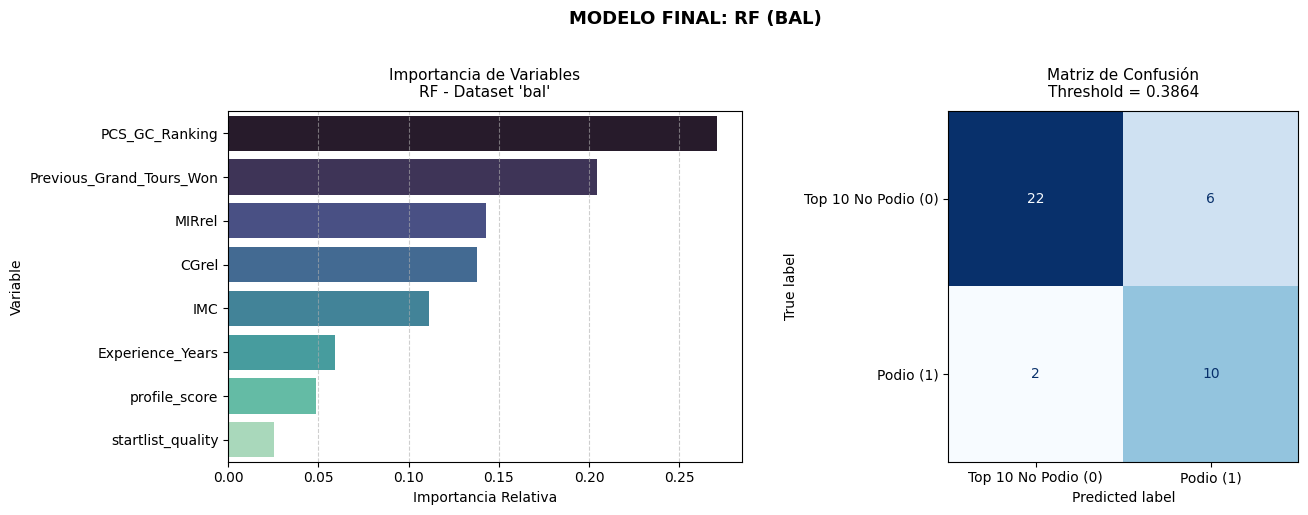

In [ ]:
# 2. RECUPERAR MODELO Y DATOS
best_model = trained_models[
    (best_dataset, best_model_name)
]

X_train_best, X_test_best = datasets[best_dataset]

# Probabilidades sobre 2021-2024
y_probs_best = best_model.predict_proba(
    X_test_best
)[:, 1]

# Predicción utilizando el threshold OOF previamente seleccionado
y_pred_best = (
    y_probs_best >= best_threshold
).astype(int)

# 3. IMPORTANCIA DE VARIABLES

model_final = best_model.named_steps["model"]

imp_final = pd.Series(
    model_final.feature_importances_,
    index=X_train_best.columns
).sort_values(ascending=False)

# 4. MATRIZ DE CONFUSIÓN

cm_final = confusion_matrix(
    y_test,
    y_pred_best
)

# 5. VISUALIZACIÓN

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# GRÁFICA IZQUIERDA: IMPORTANCIA DE VARIABLES

sns.barplot(
    x=imp_final.values,
    y=imp_final.index,
    hue=imp_final.index,
    palette="mako",
    ax=axes[0],
    legend=False
)

axes[0].set_title(
    f"Importancia de Variables\n"
    f"{best_model_name} - Dataset '{best_dataset}'",
    fontsize=11,
    pad=10
)

axes[0].set_xlabel("Importancia Relativa")
axes[0].set_ylabel("Variable")
axes[0].grid(
    axis="x",
    linestyle="--",
    alpha=0.6
)

# GRÁFICA DERECHA: MATRIZ DE CONFUSIÓN

disp_final = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "Top 10 No Podio (0)",
        "Podio (1)"
    ]
)

disp_final.plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)

axes[1].set_title(
    f"Matriz de Confusión\n"
    f"Threshold = {best_threshold:.4f}",
    fontsize=11,
    pad=10
)

axes[1].grid(False)

# TÍTULO GENERAL

fig.suptitle(
    f"MODELO FINAL: {best_model_name} ({best_dataset.upper()})",
    fontsize=13,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
from xgboost import XGBClassifier

# CONFIGURACIÓN

tscv = TimeSeriesSplit(n_splits=3)

# 2. BÚSQUEDA DE XGBOOST EN LOS DATASETS DISPONIBLES

param_xgb = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1, 2]
}

xgb_cases = []

for dataset_name, (X_train, X_test) in datasets.items():

    print("\n" + "=" * 70)
    print(f"XGBOOST | DATASET: {dataset_name.upper()}")
    print("=" * 70)

    grid_xgb = GridSearchCV(
        XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ),
        param_xgb,
        cv=tscv,
        scoring="roc_auc",
        n_jobs=-1
    )

    grid_xgb.fit(X_train, y_train)

    best_xgb_case = grid_xgb.best_estimator_

    xgb_cases.append({
        "dataset": dataset_name,
        "model": best_xgb_case,
        "best_params": grid_xgb.best_params_,
        "roc_auc_cv": grid_xgb.best_score_
    })

    print("Mejores hiperparámetros:")
    print(grid_xgb.best_params_)

    print(f"ROC-AUC CV: {grid_xgb.best_score_:.4f}")


XGBOOST | DATASET: BAL
Mejores hiperparámetros:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'reg_alpha': 0, 'reg_lambda': 1}
ROC-AUC CV: 0.6858

XGBOOST | DATASET: TOP
Mejores hiperparámetros:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'reg_alpha': 0, 'reg_lambda': 1}
ROC-AUC CV: 0.7069

XGBOOST | DATASET: FULL
Mejores hiperparámetros:
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'reg_alpha': 0, 'reg_lambda': 1}
ROC-AUC CV: 0.7081


In [ ]:
#  3. PROBABILIDADES OOF PARA XGBOOST

xgb_oof_results = []

for case in xgb_cases:

    dataset_name = case["dataset"]
    best_xgb_case = case["model"]

    X_train, X_test = datasets[dataset_name]

    oof_probs = np.full(len(X_train), np.nan)

    for train_idx, val_idx in tscv.split(X_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]

        model_fold = clone(best_xgb_case)

        model_fold.fit(
            X_tr,
            y_tr
        )

        oof_probs[val_idx] = (
            model_fold.predict_proba(X_val)[:, 1]
        )

    xgb_oof_results.append({
        "dataset": dataset_name,
        "model": best_xgb_case,
        "oof_probs": oof_probs
    })

In [ ]:
# 4. SELECCIÓN DEL THRESHOLD PARA XGBOOST

xgb_threshold_results = []

thresholds = np.linspace(0.05, 0.95, 100)

for result in xgb_oof_results:

    dataset_name = result["dataset"]
    oof_probs = result["oof_probs"]

    valid = ~np.isnan(oof_probs)

    y_oof = y_train.iloc[np.where(valid)[0]]
    p_oof = oof_probs[valid]

    for t in thresholds:

        y_pred = (p_oof >= t).astype(int)

        recall_0 = recall_score(
            y_oof,
            y_pred,
            pos_label=0,
            zero_division=0
        )

        recall_1 = recall_score(
            y_oof,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        precision_1 = precision_score(
            y_oof,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        f1_1 = f1_score(
            y_oof,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        xgb_threshold_results.append({
            "dataset": dataset_name,
            "threshold": t,
            "recall_0": recall_0,
            "recall_1": recall_1,
            "precision_1": precision_1,
            "f1_1": f1_1
        })

df_xgb_threshold = pd.DataFrame(
    xgb_threshold_results
)

In [ ]:
# 5. SELECCIÓN DEL MEJOR CASO XGBOOST

candidates_xgb = df_xgb_threshold[
    df_xgb_threshold["recall_0"] >= 0.75
].copy()

best_xgb_result = (
    candidates_xgb
    .sort_values(
        ["f1_1", "recall_1"],
        ascending=[False, False]
    )
    .iloc[0]
)

best_xgb_dataset = best_xgb_result["dataset"]
best_xgb_threshold = best_xgb_result["threshold"]

best_xgb = next(
    case["model"]
    for case in xgb_cases
    if case["dataset"] == best_xgb_dataset
)
print("\n" + "=" * 70)
print("MEJOR CASO XGBOOST")
print("=" * 70)

print(f"Dataset    : {best_xgb_dataset}")
print(f"Threshold  : {best_xgb_threshold:.4f}")
print(f"Recall 0   : {best_xgb_result['recall_0']:.4f}")
print(f"Recall 1   : {best_xgb_result['recall_1']:.4f}")
print(f"Precision 1: {best_xgb_result['precision_1']:.4f}")
print(f"F1 clase 1 : {best_xgb_result['f1_1']:.4f}")


MEJOR CASO XGBOOST
Dataset    : full
Threshold  : 0.6045
Recall 0   : 0.7564
Recall 1   : 0.4848
Precision 1: 0.4571
F1 clase 1 : 0.4706


### Análisis del sesgo y la varianza

Para analizar el comportamiento del modelo XGBoost frente a diferentes valores del *threshold*, se utilizaron múltiples modelos entrenados mediante un esquema de remuestreo temporal por bloques. En cada repetición se construyó una muestra de entrenamiento a partir de bloques temporales del conjunto de entrenamiento y se mantuvo una ventana de evaluación fija, sin utilizar el conjunto de prueba correspondiente a las ediciones 2021--2024. De esta manera, una misma observación de evaluación pudo recibir múltiples predicciones provenientes de diferentes ajustes del modelo.

Para cada observación \(i\) y cada *threshold* \(t\), las probabilidades estimadas se transformaron en decisiones binarias mediante

$$
\hat{Y}_{i,t}^{(b)}
=
I\left(\hat{p}_{i}^{(b)}\geq t\right),
$$

donde \(b\) identifica la repetición del entrenamiento. A partir de las decisiones obtenidas en las diferentes repeticiones se calculó la predicción media

$$
\overline{\hat{Y}}_{i,t}
=
\frac{1}{B}
\sum_{b=1}^{B}
\hat{Y}_{i,t}^{(b)},
$$

y la varianza de las decisiones

$$
\operatorname{Var}(\hat{Y}_{i,t})
=
\frac{1}{B}
\sum_{b=1}^{B}
\left(
\hat{Y}_{i,t}^{(b)}
-
\overline{\hat{Y}}_{i,t}
\right)^2.
$$

El sesgo se cuantificó mediante el error cuadrático entre la predicción media y la clase observada:

$$
Bias^2(t)
=
\frac{1}{n}
\sum_{i=1}^{n}
\left(
\overline{\hat{Y}}_{i,t}
-
Y_i
\right)^2.
$$

Finalmente, la varianza y el sesgo cuadrático se promediaron sobre las observaciones de la ventana de evaluación para cada valor del *threshold*. Este procedimiento permite estudiar la estabilidad de las decisiones de XGBoost ante diferentes ajustes del modelo y analizar cómo la regla de decisión modifica el comportamiento del error.


In [ ]:
#  9. PREDICCIONES REPETIDAS PARA ANALISIS DE SESGO Y VARIANZA

from sklearn.base import clone
import numpy as np
import pandas as pd

N_REPETICIONES = 30
EVAL_FRACTION = 0.25

xgb_repeated_predictions = []

X_train, X_test = datasets[best_xgb_dataset]

n = len(X_train)

n_eval = int(
    np.ceil(n * EVAL_FRACTION)
)

eval_start = n - n_eval

X_eval = X_train.iloc[eval_start:]
y_eval = y_train.iloc[eval_start:]

X_base = X_train.iloc[:eval_start]
y_base = y_train.iloc[:eval_start]

for repetition in range(N_REPETICIONES):

    rng = np.random.default_rng(
        1000 + repetition
    )

    block_size = 5

    blocks = [
        np.arange(
            i,
            min(i + block_size, len(X_base))
        )
        for i in range(
            0,
            len(X_base),
            block_size
        )
    ]

    selected_blocks = rng.choice(
        len(blocks),
        size=len(blocks),
        replace=True
    )

    train_indices = np.concatenate(
        [blocks[i] for i in selected_blocks]
    )

    X_rep = X_base.iloc[train_indices]
    y_rep = y_base.iloc[train_indices]

    model_rep = clone(best_xgb)

    model_rep.fit(
        X_rep,
        y_rep
    )

    probabilities = model_rep.predict_proba(
        X_eval
    )[:, 1]

    for idx, probability, true_value in zip(
        X_eval.index,
        probabilities,
        y_eval
    ):

        xgb_repeated_predictions.append({
            "dataset": best_xgb_dataset,
            "repetition": repetition,
            "index": idx,
            "probability": probability,
            "y_true": true_value
        })

df_xgb_repeated = pd.DataFrame(
    xgb_repeated_predictions
)

print(
    "Observaciones evaluadas:",
    df_xgb_repeated["index"].nunique()
)

print(
    "Predicciones generadas:",
    len(df_xgb_repeated)
)

Observaciones evaluadas: 38
Predicciones generadas: 1140


In [ ]:
# 10. SESGO² Y VARIANZA EN FUNCION DEL THRESHOLD

thresholds_bv = np.linspace(
    0.05,
    0.95,
    100
)

xgb_bias_variance_results = []

for t in thresholds_bv:

    df_temp = df_xgb_repeated.copy()

    df_temp["prediction"] = (
        df_temp["probability"] >= t
    ).astype(int)

    grouped = (
        df_temp
        .groupby("index")
        .agg(
            mean_prediction=("prediction", "mean"),
            variance_prediction=("prediction", "var"),
            y_true=("y_true", "first")
        )
    )

    # varianza poblacional
    grouped["variance_prediction"] = grouped[
        "variance_prediction"
    ].fillna(0)

    grouped["bias_squared"] = (
        grouped["mean_prediction"]
        - grouped["y_true"]
    ) ** 2

    grouped["squared_error"] = (
        df_temp
        .groupby("index")["prediction"]
        .apply(
            lambda x: np.mean(
                (x - grouped.loc[x.name, "y_true"]) ** 2
            )
        )
    )

    xgb_bias_variance_results.append({
        "threshold": t,
        "bias_squared": grouped["bias_squared"].mean(),
        "variance": grouped["variance_prediction"].mean(),
        "squared_error": grouped["squared_error"].mean()
    })

df_xgb_bias_variance = pd.DataFrame(
    xgb_bias_variance_results
)

df_xgb_bias_variance["bias_plus_variance"] = (
    df_xgb_bias_variance["bias_squared"]
    + df_xgb_bias_variance["variance"]
)

df_xgb_bias_variance["difference"] = (
    df_xgb_bias_variance["squared_error"]
    - df_xgb_bias_variance["bias_plus_variance"]
)

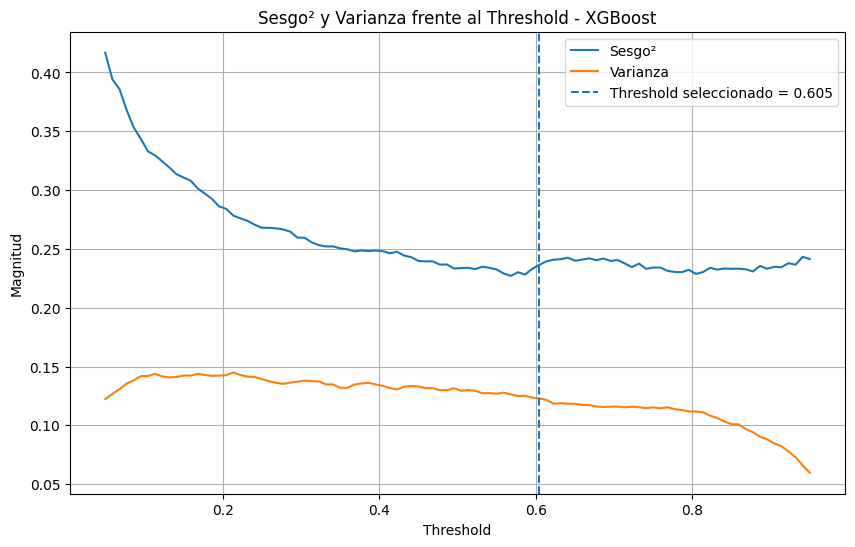

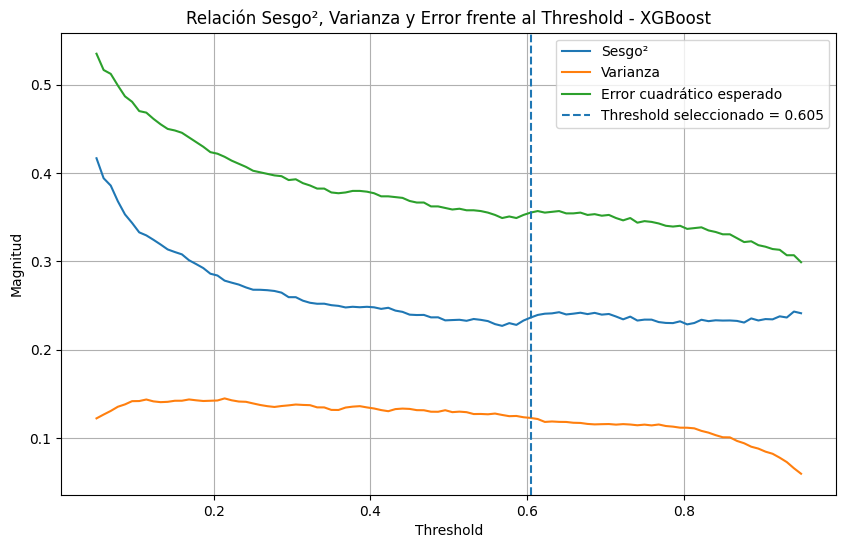

In [ ]:
# 11. GRAFICO DE SESGO² Y VARIANZA VS THRESHOLD

plt.figure(figsize=(10, 6))

plt.plot(
    df_xgb_bias_variance["threshold"],
    df_xgb_bias_variance["bias_squared"],
    label="Sesgo²"
)

plt.plot(
    df_xgb_bias_variance["threshold"],
    df_xgb_bias_variance["variance"],
    label="Varianza"
)

plt.axvline(
    best_xgb_threshold,
    linestyle="--",
    label=f"Threshold seleccionado = {best_xgb_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("Magnitud")
plt.title(
    "Sesgo² y Varianza frente al Threshold - XGBoost"
)

plt.legend()
plt.grid(True)
plt.show()
# 12. RELACION SESGO² + VARIANZA VS ERROR

plt.figure(figsize=(10, 6))

plt.plot(
    df_xgb_bias_variance["threshold"],
    df_xgb_bias_variance["bias_squared"],
    label="Sesgo²"
)

plt.plot(
    df_xgb_bias_variance["threshold"],
    df_xgb_bias_variance["variance"],
    label="Varianza"
)

plt.plot(
    df_xgb_bias_variance["threshold"],
    df_xgb_bias_variance["squared_error"],
    label="Error cuadrático esperado"
)

plt.axvline(
    best_xgb_threshold,
    linestyle="--",
    label=f"Threshold seleccionado = {best_xgb_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("Magnitud")
plt.title(
    "Relación Sesgo², Varianza y Error frente al Threshold - XGBoost"
)

plt.legend()
plt.grid(True)
plt.show()


### Análisis del sesgo y la varianza en función del *threshold*

El análisis en función del *threshold* permite estudiar cómo la regla utilizada para convertir las probabilidades estimadas por XGBoost en decisiones binarias afecta el comportamiento del modelo. Para cada valor \(t\), las probabilidades obtenidas mediante los diferentes modelos se transformaron en clasificaciones utilizando

$$
\hat{Y}_{t}=I(\hat{p}\geq t).
$$

El gráfico de \(Bias^2\) frente al *threshold* representa la discrepancia cuadrática entre la predicción media de los modelos y la clase observada. Su comportamiento permite identificar cómo cambia el error sistemático de las decisiones cuando se hace más restrictiva o más permisiva la clasificación como candidato a podio.

Por otra parte, la varianza frente al *threshold* representa la variabilidad de las decisiones producidas por los diferentes ajustes de XGBoost para una misma observación. Valores elevados indican que las decisiones son sensibles a las modificaciones realizadas en el entrenamiento, mientras que valores reducidos indican mayor estabilidad.

Finalmente, la relación entre sesgo cuadrático y varianza permite estudiar conjuntamente ambos componentes del error. Bajo el error cuadrático utilizado en este análisis se cumple, para cada observación,

$$
E[(\hat{Y}-Y)^2]
=
\left(E[\hat{Y}]-Y\right)^2
+
\operatorname{Var}(\hat{Y}),
$$

por lo que el error cuadrático esperado puede expresarse como la suma del sesgo cuadrático y la varianza. La representación frente al *threshold* permite observar cómo se modifica esta relación a medida que cambia la regla de clasificación.


In [ ]:
# 13. COMPROBACION DE LA DESCOMPOSICION

print(
    df_xgb_bias_variance[
        [
            "threshold",
            "squared_error",
            "bias_plus_variance",
            "difference"
        ]
    ].head(10)
)

print(
    "\nMáxima diferencia absoluta:",
    df_xgb_bias_variance["difference"]
    .abs()
    .max()
)

   threshold  squared_error  bias_plus_variance  difference
0   0.050000       0.535088            0.539167   -0.004079
1   0.059091       0.516667            0.520890   -0.004224
2   0.068182       0.512281            0.516640   -0.004360
3   0.077273       0.499123            0.503641   -0.004518
4   0.086364       0.486842            0.491449   -0.004607
5   0.095455       0.480702            0.485431   -0.004729
6   0.104545       0.470175            0.474908   -0.004733
7   0.113636       0.468421            0.473212   -0.004791
8   0.122727       0.461404            0.466124   -0.004721
9   0.131818       0.455263            0.459955   -0.004691

Máxima diferencia absoluta: 0.004832627545876267


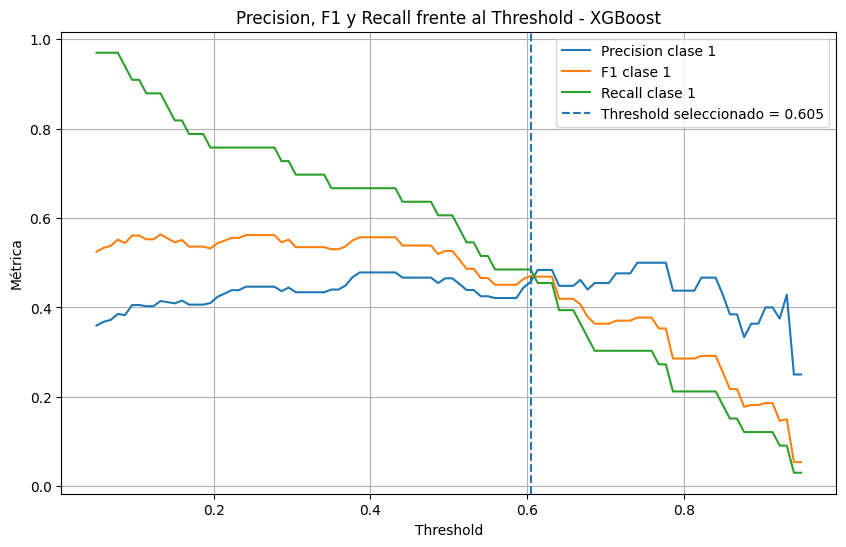

In [ ]:
# 6. GRÁFICOS DE PRECISION, F1 Y RECALL VS THRESHOLD

import matplotlib.pyplot as plt

df_plot = df_xgb_threshold[
    df_xgb_threshold["dataset"] == best_xgb_dataset
].copy()

plt.figure(figsize=(10, 6))

plt.plot(
    df_plot["threshold"],
    df_plot["precision_1"],
    label="Precision clase 1"
)

plt.plot(
    df_plot["threshold"],
    df_plot["f1_1"],
    label="F1 clase 1"
)

plt.plot(
    df_plot["threshold"],
    df_plot["recall_1"],
    label="Recall clase 1"
)

plt.axvline(
    best_xgb_threshold,
    linestyle="--",
    label=f"Threshold seleccionado = {best_xgb_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title("Precision, F1 y Recall frente al Threshold - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

### Análisis de las métricas de clasificación en función del *threshold*

Para estudiar el efecto del *threshold* sobre el desempeño de XGBoost, se utilizaron las probabilidades obtenidas mediante predicciones *Out-of-Fold* (OOF). Estas probabilidades permiten evaluar cada observación mediante un modelo que no utilizó dicha observación durante su entrenamiento. Posteriormente, para cada valor del *threshold*, las probabilidades se transformaron en decisiones binarias mediante la regla

$$
\hat{Y}=I(\hat{p}\geq t).
$$

La **precision** de la clase positiva se calculó como

$$
Precision=
\frac{TP}{TP+FP},
$$

y representa la proporción de ciclistas clasificados como candidatos a podio que efectivamente pertenecen a la clase positiva.

El **recall** de la clase positiva se calculó mediante

$$
Recall=
\frac{TP}{TP+FN},
$$

y mide la proporción de ciclistas que realmente obtuvieron un puesto de podio y fueron correctamente identificados por el modelo.

El **F1-score** combina ambas métricas mediante su media armónica:

$$
F1=
2\frac{Precision\cdot Recall}
{Precision+Recall}.
$$

Los gráficos de precision, F1 y recall frente al *threshold* permiten observar cómo cambia el comportamiento del clasificador al modificar el nivel de exigencia para asignar la clase positiva. Un *threshold* menor facilita la clasificación como candidato a podio, mientras que uno mayor hace más restrictiva dicha decisión. Por tanto, el análisis permite identificar el compromiso existente entre la identificación de los verdaderos positivos y la reducción de las predicciones positivas incorrectas.


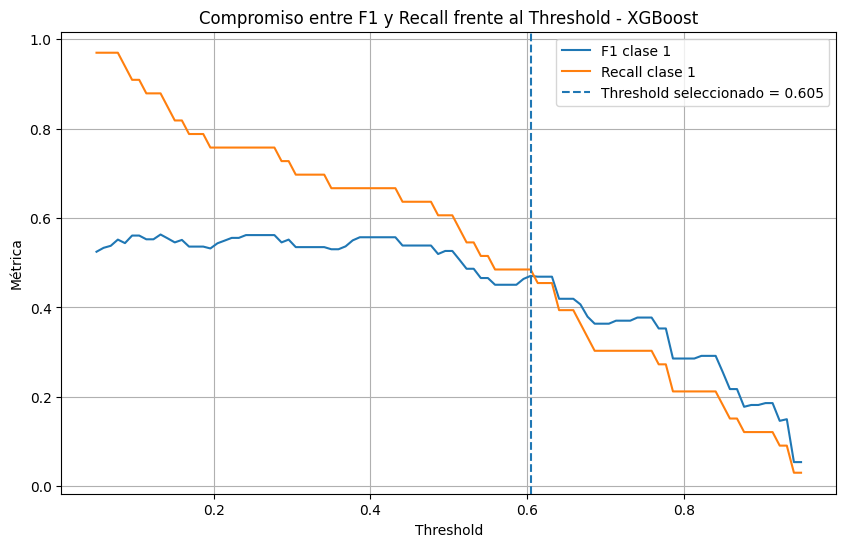

In [ ]:
# 7. COMPROMISO ENTRE F1 Y RECALL VS THRESHOLD

plt.figure(figsize=(10, 6))

plt.plot(
    df_plot["threshold"],
    df_plot["f1_1"],
    label="F1 clase 1"
)

plt.plot(
    df_plot["threshold"],
    df_plot["recall_1"],
    label="Recall clase 1"
)

plt.axvline(
    best_xgb_threshold,
    linestyle="--",
    label=f"Threshold seleccionado = {best_xgb_threshold:.3f}"
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title("Compromiso entre F1 y Recall frente al Threshold - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

### Compromiso entre F1 y *recall* frente al *threshold*

El análisis del compromiso entre F1 y *recall* permite estudiar conjuntamente la capacidad de XGBoost para identificar correctamente a los ciclistas que alcanzan el podio y el equilibrio entre recuperación y precisión de la clase positiva. Para cada valor del *threshold*, las probabilidades OOF obtenidas previamente se transformaron en decisiones binarias mediante

$$
\hat{Y}=I(\hat{p}\geq t).
$$

El *recall* mide la proporción de ciclistas que realmente alcanzaron el podio y fueron identificados correctamente por el modelo, mientras que el F1-score combina el *recall* y la *precision* mediante su media armónica. En consecuencia, un aumento del *threshold* generalmente hace más restrictiva la clasificación como candidato a podio, lo que puede reducir el número de falsos positivos, pero también puede aumentar el número de falsos negativos.

La representación conjunta de F1 y *recall* frente al *threshold* permite visualizar este comportamiento y observar cómo varía el equilibrio entre ambas métricas a medida que cambia el umbral de decisión. En particular, el análisis permite identificar la región en la que el F1 mantiene valores elevados sin producir una disminución excesiva del *recall*. El *threshold* seleccionado para XGBoost se interpreta dentro de este contexto, considerando además la restricción establecida previamente sobre el *recall* de la clase negativa.

Por tanto, esta gráfica no evalúa únicamente un punto particular del modelo, sino el comportamiento de las métricas a lo largo de diferentes reglas de decisión. Esto permite justificar el umbral seleccionado a partir del comportamiento conjunto de F1 y *recall*, en lugar de considerarlo como un valor arbitrario.


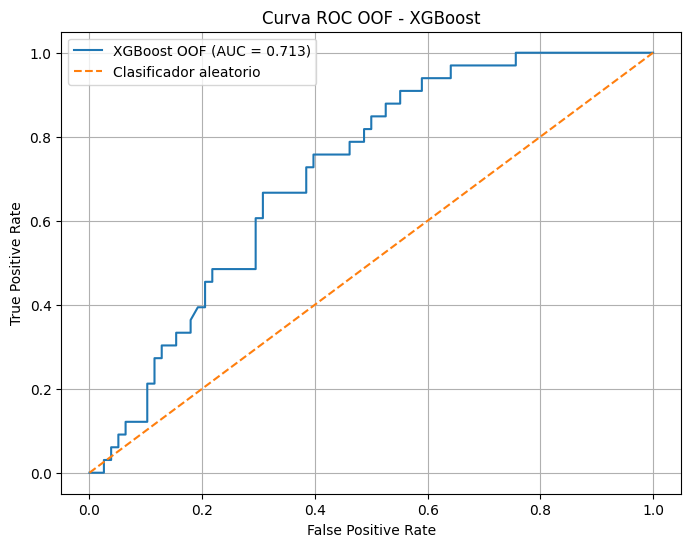

In [ ]:
# 8. CURVA ROC OOF PARA XGBOOST

from sklearn.metrics import roc_curve, roc_auc_score

valid = ~np.isnan(
    next(
        r["oof_probs"]
        for r in xgb_oof_results
        if r["dataset"] == best_xgb_dataset
    )
)

oof_probs_best = next(
    r["oof_probs"]
    for r in xgb_oof_results
    if r["dataset"] == best_xgb_dataset
)

y_oof = y_train.iloc[np.where(valid)[0]]
p_oof = oof_probs_best[valid]

fpr, tpr, roc_thresholds = roc_curve(
    y_oof,
    p_oof
)

roc_auc = roc_auc_score(
    y_oof,
    p_oof
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost OOF (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC OOF - XGBoost")
plt.legend()
plt.grid(True)
plt.show()

### Curva ROC OOF

La curva ROC de XGBoost se construyó utilizando las probabilidades obtenidas mediante el procedimiento *Out-of-Fold* (OOF). En este procedimiento, las observaciones del conjunto de entrenamiento se dividen temporalmente en diferentes particiones y cada observación es predicha por un modelo que fue entrenado únicamente con observaciones anteriores dentro del esquema de validación. De esta manera, las probabilidades utilizadas para construir la curva no corresponden a predicciones realizadas sobre los mismos datos empleados para ajustar directamente cada modelo.

La curva ROC representa la relación entre la tasa de verdaderos positivos (*True Positive Rate*, TPR) y la tasa de falsos positivos (*False Positive Rate*, FPR) para los diferentes valores posibles del *threshold*. Estas cantidades se definen como

$$
TPR=
\frac{TP}{TP+FN},
$$

y

$$
FPR=
\frac{FP}{FP+TN}.
$$

Cada punto de la curva representa el comportamiento del clasificador bajo un determinado umbral de decisión. El área bajo la curva, denominada ROC-AUC, proporciona una medida global de la capacidad discriminativa del modelo para diferenciar entre ciclistas que alcanzan el podio y aquellos que no lo alcanzan, considerando todos los umbrales posibles. Por tanto, la curva ROC OOF permite evaluar la capacidad de discriminación de XGBoost sin asociarla a un único *threshold* seleccionado previamente.


C:\Users\skorg\AppData\Local\Temp\ipykernel_2348\3229567065.py:140: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


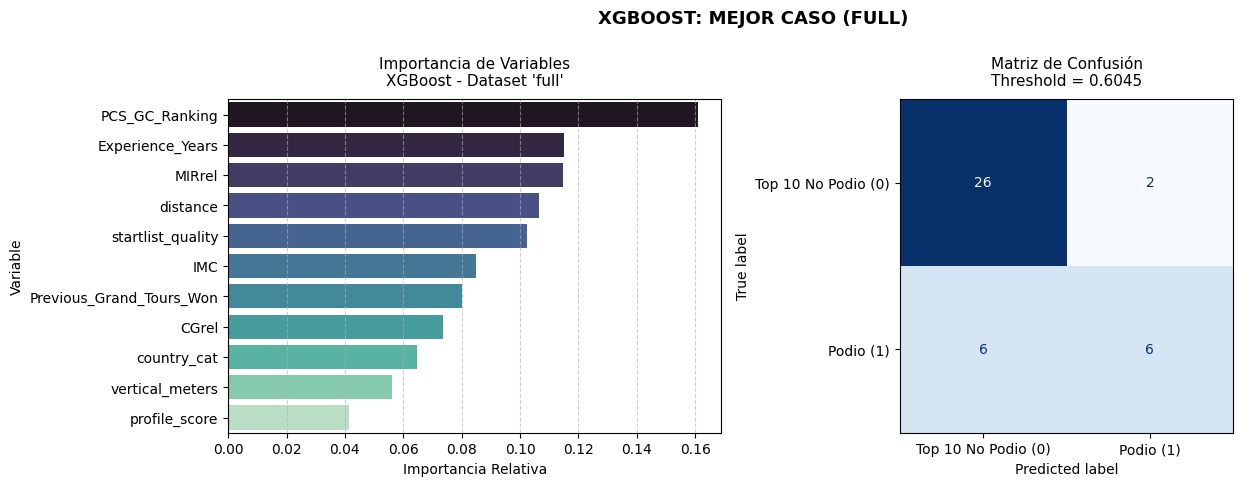

                     precision    recall  f1-score   support

Top 10 No Podio (0)     0.8125    0.9286    0.8667        28
          Podio (1)     0.7500    0.5000    0.6000        12

           accuracy                         0.8000        40
          macro avg     0.7812    0.7143    0.7333        40
       weighted avg     0.7937    0.8000    0.7867        40



In [ ]:
# 2. RECUPERAR MODELO Y DATOS

# best_xgb corresponde al mejor caso de XGBoost seleccionado mediante OOF
X_train_xgb, X_test_xgb = datasets[best_xgb_dataset]

# Probabilidades sobre 2021-2024
y_probs_xgb = best_xgb.predict_proba(
    X_test_xgb
)[:, 1]

# Predicción utilizando el threshold OOF previamente seleccionado
y_pred_xgb = (
    y_probs_xgb >= best_xgb_threshold
).astype(int)

# 3. IMPORTANCIA DE VARIABLES

imp_xgb = pd.Series(
    best_xgb.feature_importances_,
    index=X_train_xgb.columns
).sort_values(ascending=False)

# 4. MATRIZ DE CONFUSIÓN

cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

# 5. REPORTE DE CLASIFICACIÓN

reporte_xgb = classification_report(
    y_test,
    y_pred_xgb,
    target_names=[
        "Top 10 No Podio (0)",
        "Podio (1)"
    ],
    digits=4
)

# 6. VISUALIZACIÓN

fig = plt.figure(
    figsize=(14, 9)
)

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1.3, 1],
    hspace=0.35
)

# GRÁFICA IZQUIERDA: IMPORTANCIA DE VARIABLES

ax1 = fig.add_subplot(gs[0, 0])

sns.barplot(
    x=imp_xgb.values,
    y=imp_xgb.index,
    hue=imp_xgb.index,
    palette="mako",
    ax=ax1,
    legend=False
)

ax1.set_title(
    f"Importancia de Variables\n"
    f"XGBoost - Dataset '{best_xgb_dataset}'",
    fontsize=11,
    pad=10
)

ax1.set_xlabel("Importancia Relativa")
ax1.set_ylabel("Variable")

ax1.grid(
    axis="x",
    linestyle="--",
    alpha=0.6
)

# GRÁFICA DERECHA: MATRIZ DE CONFUSIÓN

ax2 = fig.add_subplot(gs[0, 1])

disp_xgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[
        "Top 10 No Podio (0)",
        "Podio (1)"
    ]
)

disp_xgb.plot(
    ax=ax2,
    cmap="Blues",
    colorbar=False
)

ax2.set_title(
    f"Matriz de Confusión\n"
    f"Threshold = {best_xgb_threshold:.4f}",
    fontsize=11,
    pad=10
)

ax2.grid(False)

# TÍTULO GENERAL

fig.suptitle(
    f"XGBOOST: MEJOR CASO ({best_xgb_dataset.upper()})",
    fontsize=13,
    fontweight="bold",
    y=0.98
)

plt.tight_layout()
plt.show()
print(reporte_xgb)

In [ ]:
# 1. RECUPERAR LOS DOS MEJORES MODELOS

# Mejor modelo entre RF / GB / Regresión Logística
best_model = trained_models[
    (best_dataset, best_model_name)
]

# Datos utilizados por el mejor modelo
X_train_best, X_test_best = datasets[best_dataset]


# Mejor caso de XGBoost
# best_xgb
# best_xgb_dataset
# best_xgb_threshold

X_train_xgb, X_test_xgb = datasets[
    best_xgb_dataset
]

print("Mejor modelo:", best_model_name)
print("Dataset:", best_dataset)

print("\nMejor XGBoost")
print("Dataset:", best_xgb_dataset)

Mejor modelo: RF
Dataset: bal

Mejor XGBoost
Dataset: full


In [ ]:
# 2. PREDICCIONES OOF DE LOS DOS MODELOS

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd

tscv_ensemble = TimeSeriesSplit(n_splits=3)

# Series indexadas para evitar problemas si los dos datasets
# tienen diferente estructura de columnas
oof_best = pd.Series(
    np.nan,
    index=y_train.index
)

oof_xgb = pd.Series(
    np.nan,
    index=y_train.index
)

# OOF DEL best_model

for train_idx, val_idx in tscv_ensemble.split(X_train_best):

    train_index = X_train_best.index[train_idx]
    val_index = X_train_best.index[val_idx]

    model_fold = clone(best_model)

    model_fold.fit(
        X_train_best.loc[train_index],
        y_train.loc[train_index]
    )

    oof_best.loc[val_index] = (
        model_fold.predict_proba(
            X_train_best.loc[val_index]
        )[:, 1]
    )

# OOF DEL best_xgb

for train_idx, val_idx in tscv_ensemble.split(X_train_xgb):

    train_index = X_train_xgb.index[train_idx]
    val_index = X_train_xgb.index[val_idx]

    xgb_fold = clone(best_xgb)

    xgb_fold.fit(
        X_train_xgb.loc[train_index],
        y_train.loc[train_index]
    )

    oof_xgb.loc[val_index] = (
        xgb_fold.predict_proba(
            X_train_xgb.loc[val_index]
        )[:, 1]
    )

In [ ]:
#  3. ALINEAR LAS PREDICCIONES OOF
df_oof_ensemble = pd.concat(
    [
        oof_best.rename("p_best_model"),
        oof_xgb.rename("p_xgb")
    ],
    axis=1
)

# Solo observaciones donde ambos modelos tienen predicción OOF
df_oof_ensemble = df_oof_ensemble.dropna()

# Variable respuesta correspondiente
y_oof_ensemble = y_train.loc[
    df_oof_ensemble.index
]

print(
    "Observaciones OOF disponibles:",
    len(df_oof_ensemble)
)

Observaciones OOF disponibles: 111


In [ ]:
# 4. PROBABILIDAD DEL ENSAMBLE

df_oof_ensemble["p_ensemble"] = (
    0.5 * df_oof_ensemble["p_best_model"]
    +
    0.5 * df_oof_ensemble["p_xgb"]
)

In [ ]:
# 5. SELECCIÓN DEL THRESHOLD DEL ENSAMBLE
from sklearn.metrics import (
    recall_score,
    precision_score,
    f1_score
)

thresholds_ensemble = np.linspace(
    0.05,
    0.95,
    100
)

resultados_ensemble = []

for threshold in thresholds_ensemble:

    pred = (
        df_oof_ensemble["p_ensemble"] >= threshold
    ).astype(int)

    recall_0 = recall_score(
        y_oof_ensemble,
        pred,
        pos_label=0,
        zero_division=0
    )

    recall_1 = recall_score(
        y_oof_ensemble,
        pred,
        pos_label=1,
        zero_division=0
    )

    precision_1 = precision_score(
        y_oof_ensemble,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1_1 = f1_score(
        y_oof_ensemble,
        pred,
        pos_label=1,
        zero_division=0
    )

    resultados_ensemble.append({
        "threshold": threshold,
        "recall_0": recall_0,
        "recall_1": recall_1,
        "precision_1": precision_1,
        "f1_1": f1_1
    })


df_resultados_ensemble = pd.DataFrame(
    resultados_ensemble
)

In [ ]:
# 6. ELEGIR EL MEJOR THRESHOLD VÁLIDO

df_validos_ensemble = df_resultados_ensemble[
    df_resultados_ensemble["recall_0"] >= 0.75
]

best_ensemble_result = (
    df_validos_ensemble
    .sort_values(
        ["f1_1", "recall_1"],
        ascending=[False, False]
    )
    .iloc[0]
)

best_ensemble_threshold = (
    best_ensemble_result["threshold"]
)

print(
    f"Threshold seleccionado para el ensamble: "
    f"{best_ensemble_threshold:.4f}"
)

print(
    f"Recall No Podio: "
    f"{best_ensemble_result['recall_0']:.4f}"
)

print(
    f"Recall Podio: "
    f"{best_ensemble_result['recall_1']:.4f}"
)

print(
    f"F1 Podio: "
    f"{best_ensemble_result['f1_1']:.4f}"
)

Threshold seleccionado para el ensamble: 0.4864
Recall No Podio: 0.7692
Recall Podio: 0.5455
F1 Podio: 0.5217


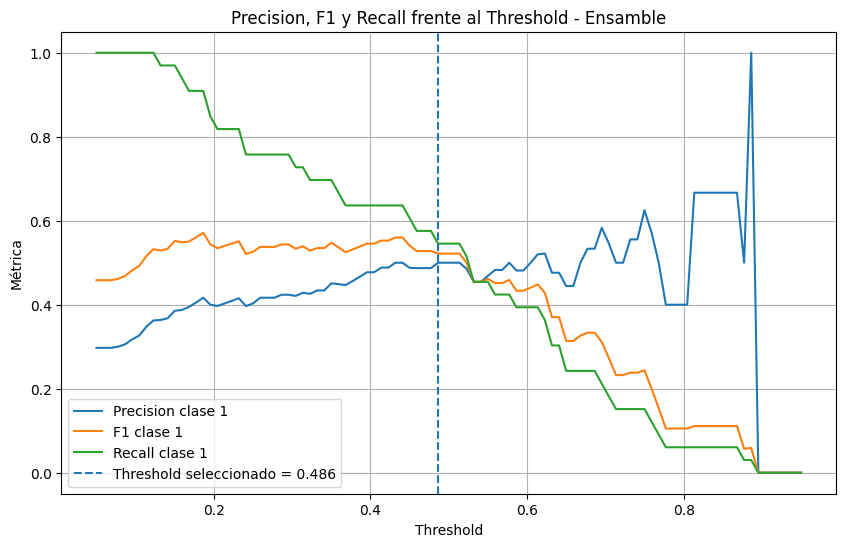

In [ ]:
# 7. PRECISION, F1 Y RECALL VS THRESHOLD

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    df_resultados_ensemble["threshold"],
    df_resultados_ensemble["precision_1"],
    label="Precision clase 1"
)

plt.plot(
    df_resultados_ensemble["threshold"],
    df_resultados_ensemble["f1_1"],
    label="F1 clase 1"
)

plt.plot(
    df_resultados_ensemble["threshold"],
    df_resultados_ensemble["recall_1"],
    label="Recall clase 1"
)

plt.axvline(
    best_ensemble_threshold,
    linestyle="--",
    label=(
        f"Threshold seleccionado = "
        f"{best_ensemble_threshold:.3f}"
    )
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title(
    "Precision, F1 y Recall frente al Threshold - Ensamble"
)

plt.legend()
plt.grid(True)
plt.show()

### Precision, F1 y recall frente al threshold

La selección del umbral de decisión permite analizar cómo varían las métricas de clasificación del ensamble ante diferentes valores de *threshold*. A partir de las probabilidades OOF obtenidas para el ensamble, se evaluaron los valores de *precision*, *F1* y *recall* de la clase positiva, correspondiente a los ciclistas que alcanzan el podio.

El análisis permite identificar el efecto que tiene el umbral sobre la capacidad del modelo para detectar correctamente los casos de podio. En general, al incrementar el *threshold*, el modelo se vuelve más restrictivo para asignar la clase positiva, lo que puede modificar el equilibrio entre *precision* y *recall*.

La siguiente gráfica muestra el comportamiento de estas tres métricas en función del *threshold*:

La línea vertical representa el *threshold* seleccionado para el ensamble mediante el criterio establecido previamente: conservar valores con un *recall* de la clase no podio de al menos \(0.75\) y, entre ellos, seleccionar el valor que maximiza el \(F1\) de la clase podio. De esta manera, el umbral utilizado posteriormente sobre el conjunto de prueba se determina exclusivamente mediante las predicciones OOF del conjunto de entrenamiento.


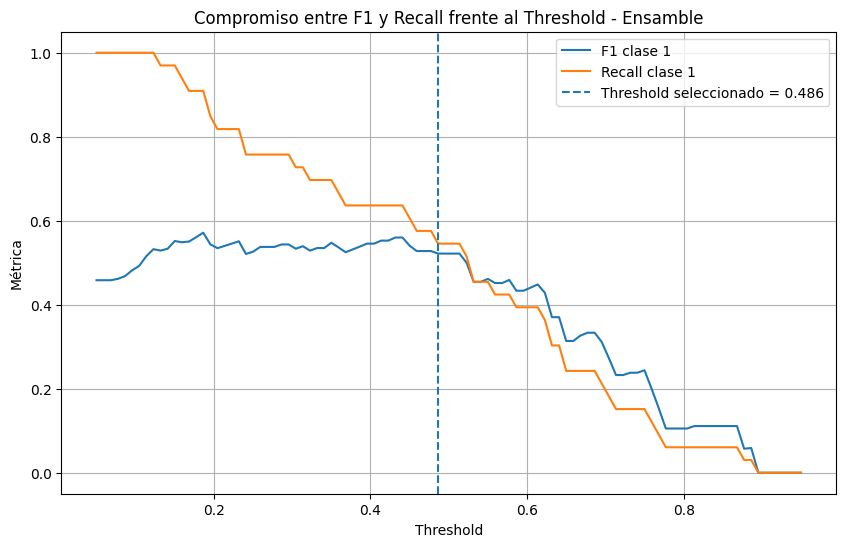

In [ ]:
# 8. COMPROMISO F1 - RECALL VS THRESHOLD

plt.figure(figsize=(10, 6))

plt.plot(
    df_resultados_ensemble["threshold"],
    df_resultados_ensemble["f1_1"],
    label="F1 clase 1"
)

plt.plot(
    df_resultados_ensemble["threshold"],
    df_resultados_ensemble["recall_1"],
    label="Recall clase 1"
)

plt.axvline(
    best_ensemble_threshold,
    linestyle="--",
    label=(
        f"Threshold seleccionado = "
        f"{best_ensemble_threshold:.3f}"
    )
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title(
    "Compromiso entre F1 y Recall frente al Threshold - Ensamble"
)

plt.legend()
plt.grid(True)
plt.show()

### Compromiso entre F1 y recall frente al threshold

Para profundizar en el comportamiento del ensamble, se analiza específicamente la relación entre el $(F1)$ y el *recall* de la clase podio en función del *threshold*. Estas métricas permiten observar el compromiso entre la capacidad del modelo para recuperar los ciclistas que efectivamente alcanzan el podio y la combinación entre precisión y recuperación.

La siguiente gráfica representa ambas métricas para los diferentes valores de *threshold* evaluados:

El gráfico permite visualizar cómo cambia la recuperación de los casos de podio al modificar el umbral y cómo este comportamiento se relaciona con el $(F1)$. El *threshold* seleccionado se identifica mediante la línea vertical, permitiendo comprobar visualmente su posición dentro del conjunto de valores considerados.

Este análisis complementa la selección numérica del umbral, ya que permite interpretar gráficamente el comportamiento del modelo antes de aplicar el criterio seleccionado al conjunto de prueba.


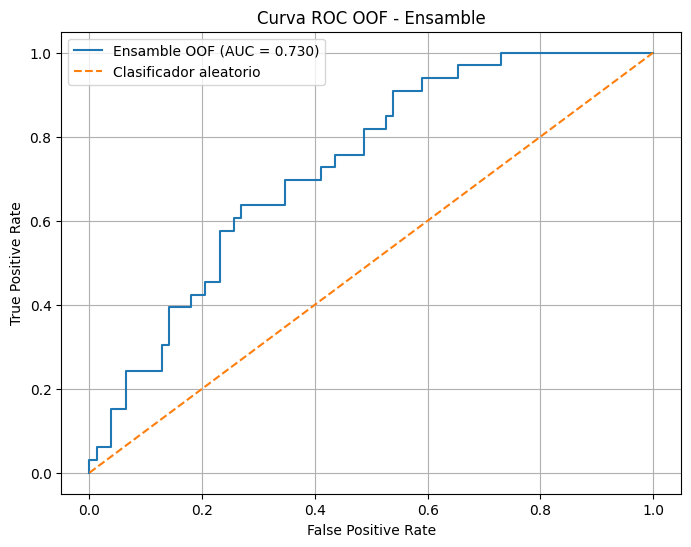

In [ ]:
# 9. CURVA ROC OOF DEL ENSAMBLE

from sklearn.metrics import roc_curve, roc_auc_score

fpr_ensemble, tpr_ensemble, thresholds_roc = roc_curve(
    y_oof_ensemble,
    df_oof_ensemble["p_ensemble"]
)

auc_ensemble = roc_auc_score(
    y_oof_ensemble,
    df_oof_ensemble["p_ensemble"]
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_ensemble,
    tpr_ensemble,
    label=f"Ensamble OOF (AUC = {auc_ensemble:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC OOF - Ensamble")

plt.legend()
plt.grid(True)
plt.show()

### Curva ROC OOF

La capacidad discriminativa del ensamble se evalúa mediante la curva ROC (*Receiver Operating Characteristic*), construida a partir de las probabilidades OOF obtenidas sobre el conjunto de entrenamiento. La curva relaciona la tasa de verdaderos positivos (*True Positive Rate*, TPR) con la tasa de falsos positivos (*False Positive Rate*, FPR) para diferentes umbrales de decisión.

A diferencia de las gráficas anteriores, la curva ROC no depende de un único *threshold*, sino que considera de manera conjunta los diferentes umbrales posibles. El área bajo la curva (ROC-AUC) proporciona una medida global de la capacidad del modelo para discriminar entre ciclistas que alcanzan y no alcanzan el podio.

La curva ROC se construye utilizando únicamente las predicciones OOF del conjunto de entrenamiento, por lo que el conjunto de prueba correspondiente a las ediciones 2021–2024 permanece completamente independiente de esta evaluación. El valor de ROC-AUC resume la capacidad discriminativa del ensamble sin depender de la elección de un *threshold* específico.


In [ ]:
# 7. EVALUACIÓN DEL ENSAMBLE EN 2021–2024

# Probabilidad del best_model
p_best_test = pd.Series(
    best_model.predict_proba(X_test_best)[:, 1],
    index=X_test_best.index
)

# Probabilidad de XGBoost
p_xgb_test = pd.Series(
    best_xgb.predict_proba(X_test_xgb)[:, 1],
    index=X_test_xgb.index
)

# Alinear ambos modelos
df_test_ensemble = pd.concat(
    [
        p_best_test.rename("p_best_model"),
        p_xgb_test.rename("p_xgb")
    ],
    axis=1,
    join="inner"
)

# Probabilidad final
df_test_ensemble["p_ensemble"] = (
    0.5 * df_test_ensemble["p_best_model"]
    +
    0.5 * df_test_ensemble["p_xgb"]
)

# Predicción final
df_test_ensemble["prediction"] = (
    df_test_ensemble["p_ensemble"]
    >= best_ensemble_threshold
).astype(int)

# Variable real
df_test_ensemble["real"] = y_test.loc[
    df_test_ensemble.index
]

print(
    "Observaciones evaluadas:",
    len(df_test_ensemble)
)

Observaciones evaluadas: 40


REPORTE DEL ENSAMBLE
                     precision    recall  f1-score   support

Top 10 No Podio (0)     0.8387    0.9286    0.8814        28
          Podio (1)     0.7778    0.5833    0.6667        12

           accuracy                         0.8250        40
          macro avg     0.8082    0.7560    0.7740        40
       weighted avg     0.8204    0.8250    0.8169        40

ROC-AUC: 0.8810


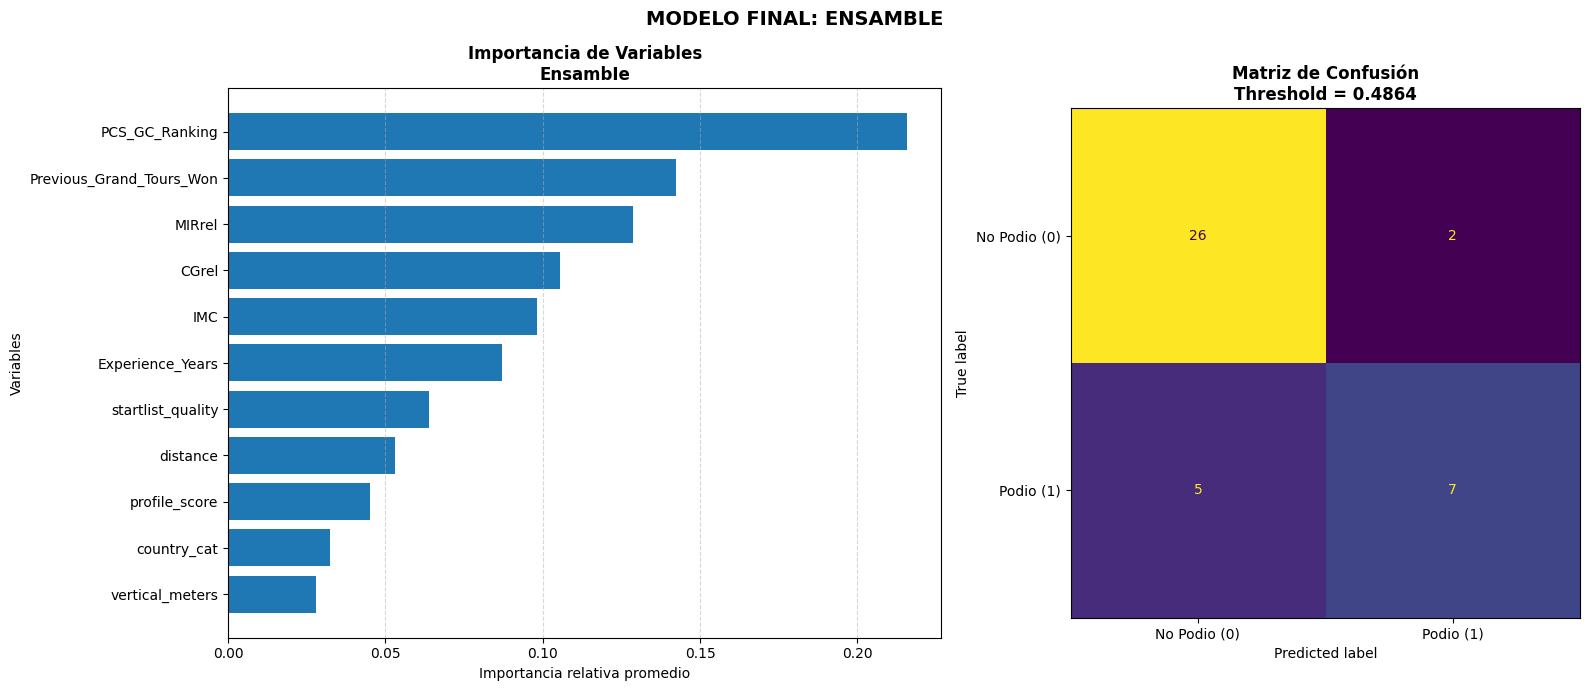

In [ ]:
# 8. MATRIZ DE CONFUSIÓN Y MÉTRICAS

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

y_test_ensemble = df_test_ensemble["real"]

y_pred_ensemble = df_test_ensemble["prediction"]

p_test_ensemble = df_test_ensemble["p_ensemble"]


# Matriz
cm_ensemble = confusion_matrix(
    y_test_ensemble,
    y_pred_ensemble
)



# ROC-AUC
roc_auc_ensemble = roc_auc_score(
    y_test_ensemble,
    p_test_ensemble
)


print("REPORTE DEL ENSAMBLE")
print("=" * 50)

print(
    classification_report(
        y_test_ensemble,
        y_pred_ensemble,
        target_names=[
            "Top 10 No Podio (0)",
            "Podio (1)"
        ],
        digits=4
    )
)

print(
    f"ROC-AUC: {roc_auc_ensemble:.4f}"
)

# 9. VISUALIZACIÓN DEL ENSAMBLE

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 9.1 IMPORTANCIA DE VARIABLES DE LOS DOS MODELOS

# Extraer los modelos internos
model_best = best_model.named_steps["model"]

# Importancias del mejor modelo anterior
imp_best = pd.Series(
    model_best.feature_importances_,
    index=X_train_best.columns,
    name="best_model"
)


# Importancias del XGBoost
imp_xgb = pd.Series(
    best_xgb.feature_importances_,
    index=X_train_xgb.columns,
    name="xgb"
)


# Normalizar cada modelo para que sean comparables
imp_best_norm = imp_best / imp_best.sum()
imp_xgb_norm = imp_xgb / imp_xgb.sum()


# Unir las variables de ambos modelos
df_importancias = pd.concat(
    [
        imp_best_norm,
        imp_xgb_norm
    ],
    axis=1
).fillna(0)


# Importancia promedio del ensamble
df_importancias["importancia_ensamble"] = (
    df_importancias["best_model"] +
    df_importancias["xgb"]
) / 2


# Ordenar de mayor a menor
df_importancias = df_importancias.sort_values(
    "importancia_ensamble",
    ascending=True
)

# 9.2 CREAR FIGURA

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7),
    gridspec_kw={"width_ratios": [1.4, 1]}
)

# 9.3 IMPORTANCIA DE VARIABLES — IZQUIERDA

axes[0].barh(
    df_importancias.index,
    df_importancias["importancia_ensamble"]
)

axes[0].set_title(
    "Importancia de Variables\nEnsambIe",
    fontsize=12,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Importancia relativa promedio"
)

axes[0].set_ylabel(
    "Variables"
)

axes[0].grid(
    axis="x",
    linestyle="--",
    alpha=0.5
)

# 9.4 MATRIZ DE CONFUSIÓN — DERECHA

disp_ensemble = ConfusionMatrixDisplay(
    confusion_matrix=cm_ensemble,
    display_labels=[
        "No Podio (0)",
        "Podio (1)"
    ]
)

disp_ensemble.plot(
    ax=axes[1],
    colorbar=False
)

axes[1].set_title(
    f"Matriz de Confusión\n"
    f"Threshold = {best_ensemble_threshold:.4f}",
    fontsize=12,
    fontweight="bold"
)

axes[1].grid(False)

# 9.5 TÍTULO GENERAL

fig.suptitle(
    "MODELO FINAL: ENSAMBLE",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.show()

In [ ]:
# 10. IDENTIFICAR CASOS BIEN Y MAL CLASIFICADOS — ENSAMBLE

# Crear DataFrame con los resultados del ensamble
df_casos_ensemble = pd.DataFrame({
    "Year": X_pruRid.loc[df_test_ensemble.index, "Year"],
    "Rider": X_pruRid.loc[df_test_ensemble.index, "Rider"],
    "Real": df_test_ensemble["real"],
    "Predicho": df_test_ensemble["prediction"],
    "Probabilidad_Podio": df_test_ensemble["p_ensemble"]
})

# Clasificación de cada caso

df_casos_ensemble["Resultado"] = np.select(
    [
        (df_casos_ensemble["Real"] == 1) &
        (df_casos_ensemble["Predicho"] == 1),

        (df_casos_ensemble["Real"] == 0) &
        (df_casos_ensemble["Predicho"] == 0),

        (df_casos_ensemble["Real"] == 0) &
        (df_casos_ensemble["Predicho"] == 1),

        (df_casos_ensemble["Real"] == 1) &
        (df_casos_ensemble["Predicho"] == 0)
    ],
    [
        "Podio correctamente detectado",
        "No podio correctamente clasificado",
        "Falso positivo",
        "Podio no detectado"
    ],
    default=""
)

# 10.1 PODIOS CORRECTAMENTE DETECTADOS

print("\n--- PODIOS CORRECTAMENTE DETECTADOS ---")

print(
    df_casos_ensemble[
        df_casos_ensemble["Resultado"] ==
        "Podio correctamente detectado"
    ][
        ["Year", "Rider", "Probabilidad_Podio"]
    ].to_string(index=False)
)

# 10.2 PODIOS NO DETECTADOS

print("\n--- PODIOS NO DETECTADOS ---")

print(
    df_casos_ensemble[
        df_casos_ensemble["Resultado"] ==
        "Podio no detectado"
    ][
        ["Year", "Rider", "Probabilidad_Podio"]
    ].to_string(index=False)
)

# 10.3 FALSOS POSITIVOS

print("\n--- FALSOS PODIOS ---")

print(
    df_casos_ensemble[
        df_casos_ensemble["Resultado"] ==
        "Falso positivo"
    ][
        ["Year", "Rider", "Probabilidad_Podio"]
    ].to_string(index=False)
)


--- PODIOS CORRECTAMENTE DETECTADOS ---
 Year            Rider  Probabilidad_Podio
 2021    Tadej Pogacar            0.768540
 2021  Richard Carapaz            0.622787
 2022    Tadej Pogacar            0.769813
 2023    Tadej Pogacar            0.862763
 2024    Tadej Pogacar            0.866021
 2024 Jonas Vingegaard            0.820885
 2024  Remco Evenepoel            0.597043

--- PODIOS NO DETECTADOS ---
 Year            Rider  Probabilidad_Podio
 2021 Jonas Vingegaard            0.137816
 2022 Jonas Vingegaard            0.182341
 2022   Geraint Thomas            0.472021
 2023 Jonas Vingegaard            0.475401
 2023       Adam Yates            0.294792

--- FALSOS PODIOS ---
 Year            Rider  Probabilidad_Podio
 2024     Joao Almeida            0.660782
 2024 Carlos Rodriguez            0.525224


## Prueba extra 2025-2026

In [78]:
import pandas as pd
Df_pru=pd.read_csv('Data2526.csv', sep=';')
Df_pru.info()

def minmax_by_year(X, column):
    return X.groupby('Year')[column].transform(
        lambda x: (x - x.min()) / (x.max() - x.min())
    )
Df_pru['CG'] = pd.to_numeric(
    Df_pru['CG'].str.replace(',', '.', regex=False),
    errors='coerce'
)
Df_pru['MIR'] = pd.to_numeric(
    Df_pru['MIR'].str.replace(',', '.', regex=False),
    errors='coerce'
)
Df_pru['IMC'] = pd.to_numeric(
    Df_pru['IMC'].str.replace(',', '.', regex=False),
    errors='coerce'
)

Df_pru['CGrel'] = minmax_by_year(Df_pru, 'CG')
Df_pru['MIRrel'] = minmax_by_year(Df_pru, 'MIR' )

Df_pru['podio'] = (Df_pru['Position'] <= 3).astype(int)
y=Df_pru['podio']
X_pru= Df_pru.drop(columns=['podio', 'Position','CG','MIR','Rider','Year'])
X_pru.columns = X_pru.columns.str.strip()
print("Entrenamiento:", repr(X_train_full.columns.tolist()))
print("Nuevo:", repr(X_pru.columns.tolist()))
y_pru=y


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Year                      20 non-null     int64 
 1   Position                  20 non-null     int64 
 2   Rider                     20 non-null     object
 3   Experience_Years          20 non-null     int64 
 4   Previous_Grand_Tours_Won  20 non-null     int64 
 5   distance                  20 non-null     int64 
 6   vertical_meters           20 non-null     int64 
 7   profile_score             20 non-null     int64 
 8   startlist_quality         20 non-null     int64 
 9   IMC                       20 non-null     object
 10  CG                        20 non-null     object
 11  MIR                       20 non-null     object
 12   country_cat              20 non-null     int64 
 13  PCS_GC_Ranking            20 non-null     int64 
dtypes: int64(10), object(4)
memo

Columnas del mejor modelo:
['Previous_Grand_Tours_Won', 'CGrel', 'MIRrel', 'IMC', 'Experience_Years', 'startlist_quality', 'profile_score', 'PCS_GC_Ranking']

Columnas de XGBoost:
['Experience_Years', 'Previous_Grand_Tours_Won', 'distance', 'vertical_meters', 'IMC', 'CGrel', 'MIRrel', 'profile_score', 'country_cat', 'startlist_quality', 'PCS_GC_Ranking']


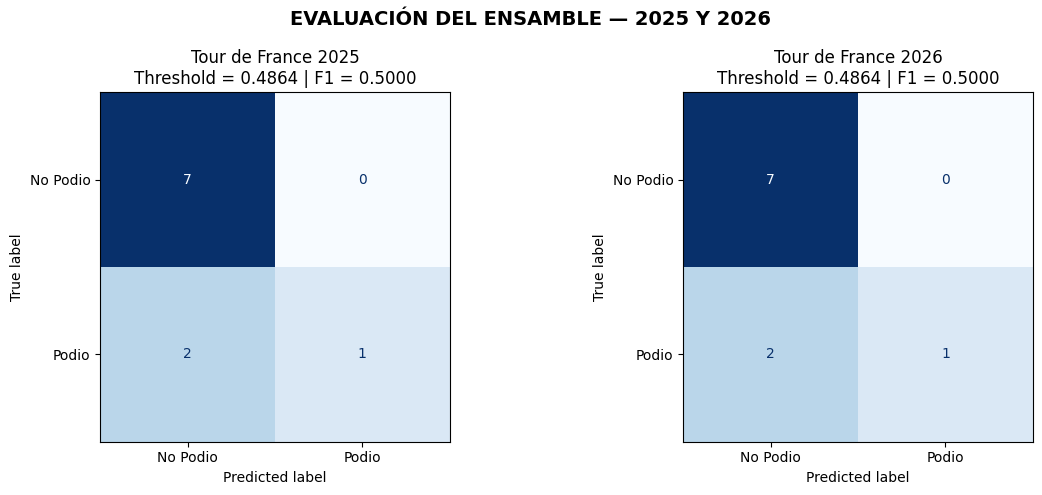

EVALUACIÓN DEL ENSAMBLE — 2025 Y 2026
              precision    recall  f1-score   support

    No Podio     0.7778    1.0000    0.8750        14
       Podio     1.0000    0.3333    0.5000         6

    accuracy                         0.8000        20
   macro avg     0.8889    0.6667    0.6875        20
weighted avg     0.8444    0.8000    0.7625        20

ROC-AUC: 0.8214

TOUR DE FRANCE 2025
              precision    recall  f1-score   support

    No Podio     0.7778    1.0000    0.8750         7
       Podio     1.0000    0.3333    0.5000         3

    accuracy                         0.8000        10
   macro avg     0.8889    0.6667    0.6875        10
weighted avg     0.8444    0.8000    0.7625        10

ROC-AUC: 0.7143

TOUR DE FRANCE 2026
              precision    recall  f1-score   support

    No Podio     0.7778    1.0000    0.8750         7
       Podio     1.0000    0.3333    0.5000         3

    accuracy                         0.8000        10
   macro avg    

In [ ]:
# EVALUACIÓN OUT-OF-SAMPLE — TOUR DE FRANCE 2025 Y 2026
# ENSAMBLE FINAL

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    f1_score,
    recall_score,
    precision_score
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. PREPARAR LOS DATOS PARA CADA MODELO

# Variables utilizadas por el mejor modelo seleccionado
X_new_best = X_pru[X_train_best.columns]


# Variables utilizadas por XGBoost
X_new_xgb = X_pru[X_train_xgb.columns]


# Variable real
y_new = y_pru


# Verificación de columnas
print("Columnas del mejor modelo:")
print(X_new_best.columns.tolist())

print("\nColumnas de XGBoost:")
print(X_new_xgb.columns.tolist())

# 2. PROBABILIDADES DE LOS DOS MODELOS

p_best_new = best_model.predict_proba(
    X_new_best
)[:, 1]


p_xgb_new = best_xgb.predict_proba(
    X_new_xgb
)[:, 1]

# 3. ENSAMBLE FINAL

p_ens_new = (
    0.5 * p_best_new +
    0.5 * p_xgb_new
)

# 4. CLASIFICACIÓN CON EL THRESHOLD DEFINITIVO

pred_ens_new = (
    p_ens_new >= best_ensemble_threshold
).astype(int)

# 5. CREAR DATAFRAME DE RESULTADOS

df_eval_new = pd.DataFrame({
    "Year": Df_pru["Year"].to_numpy(),
    "Rider": Df_pru["Rider"].to_numpy(),
    "Real": y_new.to_numpy(),
    "Probabilidad_Podio": p_ens_new,
    "Predicho": pred_ens_new
})

# 6. IDENTIFICAR RESULTADOS

df_eval_new["Resultado"] = np.select(
    [
        (df_eval_new["Real"] == 1) &
        (df_eval_new["Predicho"] == 1),

        (df_eval_new["Real"] == 0) &
        (df_eval_new["Predicho"] == 0),

        (df_eval_new["Real"] == 0) &
        (df_eval_new["Predicho"] == 1),

        (df_eval_new["Real"] == 1) &
        (df_eval_new["Predicho"] == 0)
    ],
    [
        "Podio correctamente detectado",
        "No podio correctamente clasificado",
        "Falso positivo",
        "Podio no detectado"
    ],
    default=""
)

# 7. MATRICES DE CONFUSIÓN — 2025 Y 2026

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


for ax, year in zip(axes, [2025, 2026]):

    df_year = df_eval_new[
        df_eval_new["Year"] == year
    ]

    cm = confusion_matrix(
        df_year["Real"],
        df_year["Predicho"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Podio",
            "Podio"
        ]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    f1 = f1_score(
        df_year["Real"],
        df_year["Predicho"],
        zero_division=0
    )

    ax.set_title(
        f"Tour de France {year}\n"
        f"Threshold = {best_ensemble_threshold:.4f} | "
        f"F1 = {f1:.4f}"
    )

    ax.grid(False)


plt.suptitle(
    "EVALUACIÓN DEL ENSAMBLE — 2025 Y 2026",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 8. REPORTE GENERAL 2025–2026

print("=" * 70)
print("EVALUACIÓN DEL ENSAMBLE — 2025 Y 2026")
print("=" * 70)

print(
    classification_report(
        y_new,
        pred_ens_new,
        target_names=[
            "No Podio",
            "Podio"
        ],
        digits=4,
        zero_division=0
    )
)

roc_auc_new = roc_auc_score(
    y_new,
    p_ens_new
)

print(
    f"ROC-AUC: {roc_auc_new:.4f}"
)

# 9. EVALUACIÓN POR EDICIÓN

for year in [2025, 2026]:

    df_year = df_eval_new[
        df_eval_new["Year"] == year
    ]

    y_year = df_year["Real"]
    pred_year = df_year["Predicho"]
    p_year = df_year["Probabilidad_Podio"]

    print("\n" + "=" * 70)
    print(f"TOUR DE FRANCE {year}")
    print("=" * 70)

    print(
        classification_report(
            y_year,
            pred_year,
            target_names=[
                "No Podio",
                "Podio"
            ],
            digits=4,
            zero_division=0
        )
    )

    # ROC-AUC solo si existen las dos clases
    if y_year.nunique() == 2:

        roc_auc_year = roc_auc_score(
            y_year,
            p_year
        )

        print(
            f"ROC-AUC: {roc_auc_year:.4f}"
        )

# 10. PODIOS CORRECTAMENTE DETECTADOS

print("\n" + "=" * 70)
print("PODIOS CORRECTAMENTE DETECTADOS")
print("=" * 70)

print(
    df_eval_new[
        df_eval_new["Resultado"] ==
        "Podio correctamente detectado"
    ][
        [
            "Year",
            "Rider",
            "Probabilidad_Podio"
        ]
    ].to_string(index=False)
)

# 11. PODIOS NO DETECTADOS

print("\n" + "=" * 70)
print("PODIOS NO DETECTADOS")
print("=" * 70)

print(
    df_eval_new[
        df_eval_new["Resultado"] ==
        "Podio no detectado"
    ][
        [
            "Year",
            "Rider",
            "Probabilidad_Podio"
        ]
    ].to_string(index=False)
)

# 12. FALSOS POSITIVOS

print("\n" + "=" * 70)
print("FALSOS POSITIVOS")
print("=" * 70)

print(
    df_eval_new[
        df_eval_new["Resultado"] ==
        "Falso positivo"
    ][
        [
            "Year",
            "Rider",
            "Probabilidad_Podio"
        ]
    ].to_string(index=False)
)

# 13. RESUMEN POR EDICIÓN

print("\n" + "=" * 70)
print("RESUMEN POR EDICIÓN")
print("=" * 70)

resumen = []

for year in [2025, 2026]:

    df_year = df_eval_new[
        df_eval_new["Year"] == year
    ]

    resumen.append({
        "Year": year,
        "Observaciones": len(df_year),
        "Podios reales": int(df_year["Real"].sum()),
        "Podios predichos": int(df_year["Predicho"].sum()),
        "F1 Podio": f1_score(
            df_year["Real"],
            df_year["Predicho"],
            zero_division=0
        ),
        "Recall Podio": recall_score(
            df_year["Real"],
            df_year["Predicho"],
            zero_division=0
        ),
        "Precision Podio": precision_score(
            df_year["Real"],
            df_year["Predicho"],
            zero_division=0
        )
    })

df_resumen_new = pd.DataFrame(resumen)

print(
    df_resumen_new.to_string(index=False)
)

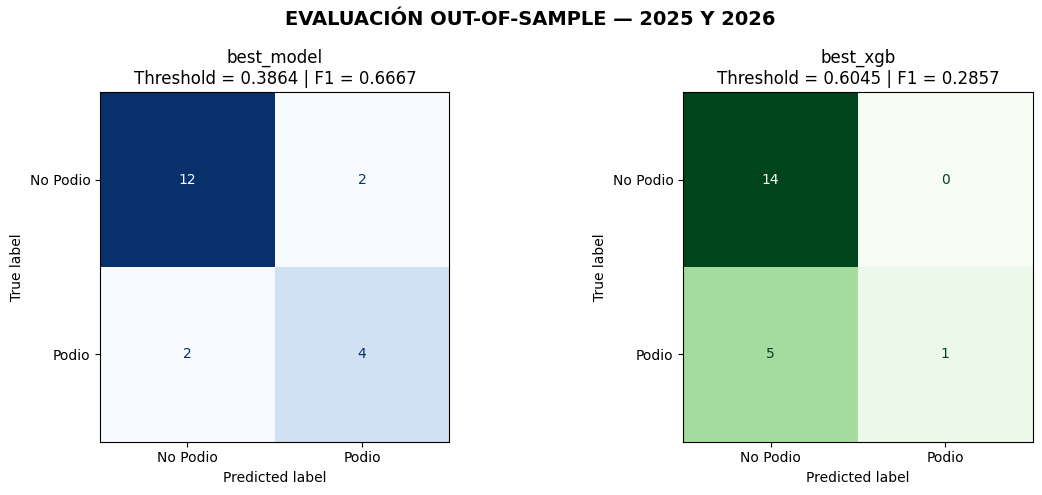

best_model
              precision    recall  f1-score   support

    No Podio     0.8571    0.8571    0.8571        14
       Podio     0.6667    0.6667    0.6667         6

    accuracy                         0.8000        20
   macro avg     0.7619    0.7619    0.7619        20
weighted avg     0.8000    0.8000    0.8000        20

best_xgb
              precision    recall  f1-score   support

    No Podio     0.7368    1.0000    0.8485        14
       Podio     1.0000    0.1667    0.2857         6

    accuracy                         0.7500        20
   macro avg     0.8684    0.5833    0.5671        20
weighted avg     0.8158    0.7500    0.6797        20

ROC-AUC
best_model : 0.7381
best_xgb   : 0.8095


In [ ]:
# EVALUACIÓN DE best_model Y best_xgb — DATOS 2025–2026
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    f1_score,
    recall_score,
    precision_score
)

import numpy as np
import matplotlib.pyplot as plt

# 1. PREPARAR LOS DATOS

# Variables correspondientes a cada modelo
X_new_best = X_pru[X_train_best.columns]

X_new_xgb = X_pru[X_train_xgb.columns]

# Valores reales
y_new = y_pru

# 2. PROBABILIDADES

p_best_new = best_model.predict_proba(
    X_new_best
)[:, 1]

p_xgb_new = best_xgb.predict_proba(
    X_new_xgb
)[:, 1]

# 3. CLASIFICACIONES

pred_best_new = (
    p_best_new >= best_threshold
).astype(int)

pred_xgb_new = (
    p_xgb_new >= best_xgb_threshold
).astype(int)

# 4. MATRICES DE CONFUSIÓN

cm_best = confusion_matrix(
    y_new,
    pred_best_new
)

cm_xgb = confusion_matrix(
    y_new,
    pred_xgb_new
)

# 5. VISUALIZACIÓN

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

# best_model

disp_best = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=[
        "No Podio",
        "Podio"
    ]
)

disp_best.plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)

f1_best = f1_score(
    y_new,
    pred_best_new,
    zero_division=0
)

axes[0].set_title(
    f"best_model\n"
    f"Threshold = {best_threshold:.4f} | "
    f"F1 = {f1_best:.4f}"
)

axes[0].grid(False)

# best_xgb

disp_xgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=[
        "No Podio",
        "Podio"
    ]
)

disp_xgb.plot(
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)

f1_xgb = f1_score(
    y_new,
    pred_xgb_new,
    zero_division=0
)

axes[1].set_title(
    f"best_xgb\n"
    f"Threshold = {best_xgb_threshold:.4f} | "
    f"F1 = {f1_xgb:.4f}"
)

axes[1].grid(False)

# Título general

plt.suptitle(
    "EVALUACIÓN OUT-OF-SAMPLE — 2025 Y 2026",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# 6. REPORTES DE CLASIFICACIÓN

print("=" * 70)
print("best_model")
print("=" * 70)

print(
    classification_report(
        y_new,
        pred_best_new,
        target_names=[
            "No Podio",
            "Podio"
        ],
        digits=4,
        zero_division=0
    )
)


print("=" * 70)
print("best_xgb")
print("=" * 70)

print(
    classification_report(
        y_new,
        pred_xgb_new,
        target_names=[
            "No Podio",
            "Podio"
        ],
        digits=4,
        zero_division=0
    )
)

# 7. ROC-AUC
roc_auc_best = roc_auc_score(
    y_new,
    p_best_new
)

roc_auc_xgb = roc_auc_score(
    y_new,
    p_xgb_new
)

print("=" * 70)
print("ROC-AUC")
print("=" * 70)

print(
    f"best_model : {roc_auc_best:.4f}"
)

print(
    f"best_xgb   : {roc_auc_xgb:.4f}"
)

Probabilidades, hombres del podio en XGBoost.

In [81]:
df_xgb_2526 = pd.DataFrame({
    "Year": Df_pru["Year"].to_numpy(),
    "Rider": Df_pru["Rider"].to_numpy(),
    "Real": y_pru.to_numpy(),
    "Prob_XGB": p_xgb_new,
    "Pred_XGB": pred_xgb_new
})

print(
    df_xgb_2526[
        df_xgb_2526["Real"] == 1
    ][
        [
            "Year",
            "Rider",
            "Prob_XGB",
            "Pred_XGB"
        ]
    ].to_string(index=False)
)

 Year            Rider  Prob_XGB  Pred_XGB
 2025   Tadej Pogačar   0.147086         0
 2025 Jonas Vingegaard  0.431448         0
 2025 Florian Lipowitz  0.089797         0
 2026   Tadej Pogačar   0.663108         1
 2026  Remco Evenepoel  0.017765         0
 2026   Isaac Del Toro  0.411018         0


Resultados Ranking 25-26

In [ ]:
resultados_2526_ranking = {}

for name, (X_tr, X_te) in datasets.items():

    print(f"\n================ CONJUNTO: {name.upper()} ================")

    # Columnas utilizadas por este conjunto de datos

    feature_columns = X_tr.columns.tolist()

    # X_pru contiene las mismas variables predictoras,
    # pero no contiene Year ni Rider
    X_new = X_pru[feature_columns].copy()

    # Recuperar modelos ya entrenados
    xgb_model = modelos_ranking[name]["xgb"]
    lgb_model = modelos_ranking[name]["lgb"]

    # Obtener scores de ranking

    xgb_scores = xgb_model.predict(X_new)
    lgb_scores = lgb_model.predict(X_new)

    # Construir dataframe de resultados

    df_rank = pd.DataFrame({
        "Year": Df_pru["Year"].values,
        "Rider": Df_pru["Rider"].values,
        "Position": Df_pru["Position"].values,
        "XGB_Score": xgb_scores,
        "LGB_Score": lgb_scores
    })

    resultados_2526_ranking[name] = df_rank

    print(df_rank.head())
    


================ CONJUNTO: BAL ================
   Year             Rider  Position  XGB_Score  LGB_Score
0  2025    Tadej Pogačar          1   1.335355   0.104821
1  2025  Jonas Vingegaard         2  -0.865943   0.588741
2  2025  Florian Lipowitz         3  -1.529702  -2.815398
3  2025       Oscar Onley         4  -0.982857  -0.961318
4  2025        Felix Gall         5  -3.381407  -4.472656

================ CONJUNTO: TOP ================
   Year             Rider  Position  XGB_Score  LGB_Score
0  2025    Tadej Pogačar          1   0.849595   0.934769
1  2025  Jonas Vingegaard         2  -0.243423   0.382940
2  2025  Florian Lipowitz         3  -2.126797  -2.240096
3  2025       Oscar Onley         4  -0.706757  -0.104336
4  2025        Felix Gall         5  -3.127937  -3.876996

================ CONJUNTO: FULL ================
   Year             Rider  Position  XGB_Score  LGB_Score
0  2025    Tadej Pogačar          1   1.065975  -0.182498
1  2025  Jonas Vingegaard         2  -0.

Podios:

In [83]:
for name, df_rank in resultados_2526_ranking.items():

    print(f"\n\n========================================")
    print(f"CONJUNTO: {name.upper()}")
    print(f"========================================")

    for year in sorted(df_rank["Year"].unique()):

        df_year = df_rank[df_rank["Year"] == year].copy()

        top3_xgb = (
            df_year
            .sort_values("XGB_Score", ascending=False)
            .head(3)
        )

        top3_lgb = (
            df_year
            .sort_values("LGB_Score", ascending=False)
            .head(3)
        )

        print(f"\n---------- TOUR {year} ----------")

        print("\nXGBoost Ranker - Top 3:")
        print(
            top3_xgb[
                ["Rider", "Position", "XGB_Score"]
            ].to_string(index=False)
        )

        print("\nLightGBM Ranker - Top 3:")
        print(
            top3_lgb[
                ["Rider", "Position", "LGB_Score"]
            ].to_string(index=False)
        )



CONJUNTO: BAL

---------- TOUR 2025 ----------

XGBoost Ranker - Top 3:
           Rider  Position  XGB_Score
  Tadej Pogačar          1   1.335355
   Primož Roglič         8  -0.702782
Jonas Vingegaard         2  -0.865943

LightGBM Ranker - Top 3:
           Rider  Position  LGB_Score
Jonas Vingegaard         2   0.588741
  Tadej Pogačar          1   0.104821
   Primož Roglič         8  -0.930806

---------- TOUR 2026 ----------

XGBoost Ranker - Top 3:
         Rider  Position  XGB_Score
Tadej Pogačar          1   1.310479
Isaac Del Toro         3   0.389389
Thomas Pidcock         9  -0.138436

LightGBM Ranker - Top 3:
         Rider  Position  LGB_Score
Tadej Pogačar          1   1.509205
Isaac Del Toro         3   0.049772
Thomas Pidcock         9  -0.447507


CONJUNTO: TOP

---------- TOUR 2025 ----------

XGBoost Ranker - Top 3:
           Rider  Position  XGB_Score
  Tadej Pogačar          1   0.849595
Jonas Vingegaard         2  -0.243423
   Primož Roglič         8  -0.67230

In [84]:
metricas_2526 = []

for name, df_rank in resultados_2526_ranking.items():

    for year in sorted(df_rank["Year"].unique()):

        df_year = df_rank[df_rank["Year"] == year].copy()

        # Podio real
        podio_real = set(
            df_year.loc[
                df_year["Position"] <= 3,
                "Rider"
            ]
        )

        # Top 3 predicho por XGBoost
        top3_xgb = set(
            df_year
            .sort_values("XGB_Score", ascending=False)
            .head(3)["Rider"]
        )

        # Top 3 predicho por LightGBM
        top3_lgb = set(
            df_year
            .sort_values("LGB_Score", ascending=False)
            .head(3)["Rider"]
        )

        # Aciertos
        aciertos_xgb = len(podio_real & top3_xgb)
        aciertos_lgb = len(podio_real & top3_lgb)

        metricas_2526.append({
            "Conjunto": name,
            "Year": year,

            "XGB_Aciertos": aciertos_xgb,
            "XGB_Precision@3": aciertos_xgb / 3,

            "LGB_Aciertos": aciertos_lgb,
            "LGB_Precision@3": aciertos_lgb / 3,

            "Podio_Completo_XGB": aciertos_xgb == 3,
            "Podio_Completo_LGB": aciertos_lgb == 3
        })

df_metricas_2526 = pd.DataFrame(metricas_2526)

df_metricas_2526

,Conjunto,Year,XGB_Aciertos,XGB_Precision@3,LGB_Aciertos,LGB_Precision@3,Podio_Completo_XGB,Podio_Completo_LGB
0,bal,2025,2,0.666667,2,0.666667,False,False
1,bal,2026,2,0.666667,2,0.666667,False,False
2,top,2025,2,0.666667,2,0.666667,False,False
3,top,2026,2,0.666667,2,0.666667,False,False
4,full,2025,1,0.333333,2,0.666667,False,False
5,full,2026,3,1.000000,2,0.666667,True,False


In [85]:
for name, df_rank in resultados_2526_ranking.items():

    print(f"\n================ {name.upper()} ================")

    for year in sorted(df_rank["Year"].unique()):

        df_year = df_rank[df_rank["Year"] == year].copy()

        # Podio real ordenado
        podio_real = (
            df_year[
                df_year["Position"] <= 3
            ]
            .sort_values("Position")
            ["Rider"]
            .tolist()
        )

        # Podio XGB ordenado por score
        podio_xgb = (
            df_year
            .sort_values("XGB_Score", ascending=False)
            .head(3)
            ["Rider"]
            .tolist()
        )

        # Podio LGB ordenado por score
        podio_lgb = (
            df_year
            .sort_values("LGB_Score", ascending=False)
            .head(3)
            ["Rider"]
            .tolist()
        )

        exacto_xgb = podio_real == podio_xgb
        exacto_lgb = podio_real == podio_lgb

        print(f"\nTour {year}")

        print("Real :", podio_real)
        print("XGB  :", podio_xgb)
        print("LGB  :", podio_lgb)

        print("Orden exacto XGB:", exacto_xgb)
        print("Orden exacto LGB:", exacto_lgb)


================ BAL ================

Tour 2025
Real : ['Tadej Pogačar\xa0', 'Jonas Vingegaard', 'Florian Lipowitz']
XGB  : ['Tadej Pogačar\xa0', 'Primož Roglič', 'Jonas Vingegaard']
LGB  : ['Jonas Vingegaard', 'Tadej Pogačar\xa0', 'Primož Roglič']
Orden exacto XGB: False
Orden exacto LGB: False

Tour 2026
Real : ['Tadej Pogačar\xa0', 'Remco Evenepoel', 'Isaac Del Toro']
XGB  : ['Tadej Pogačar\xa0', 'Isaac Del Toro', 'Thomas Pidcock']
LGB  : ['Tadej Pogačar\xa0', 'Isaac Del Toro', 'Thomas Pidcock']
Orden exacto XGB: False
Orden exacto LGB: False

================ TOP ================

Tour 2025
Real : ['Tadej Pogačar\xa0', 'Jonas Vingegaard', 'Florian Lipowitz']
XGB  : ['Tadej Pogačar\xa0', 'Jonas Vingegaard', 'Primož Roglič']
LGB  : ['Tadej Pogačar\xa0', 'Jonas Vingegaard', 'Oscar Onley']
Orden exacto XGB: False
Orden exacto LGB: False

Tour 2026
Real : ['Tadej Pogačar\xa0', 'Remco Evenepoel', 'Isaac Del Toro']
XGB  : ['Isaac Del Toro', 'Remco Evenepoel', 'Thomas Pidcock']
LGB  : ['